## Notebook setup and reusable functions

I start by importing the libraries used for data handling, visualisation, statistical comparisons, and model fitting. I set the input and output paths and define two switches that control whether I retrain the models or load the saved results, and whether I run the additional experiments. I then load the saved bundle when retraining is turned off. Finally, I define reusable functions: `family()` groups variables by their feature family, while `psi()` calculates the Population Stability Index (PSI) between a reference period and a later period, treating missing values as a separate group. These functions are used throughout the dataset and drift analysis.


In [2]:
import os, time, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from scipy.stats import spearmanr, ks_2samp, wasserstein_distance
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, OneHotEncoder
warnings.filterwarnings("ignore")

# ---- paths -------------------------------------------------------------
DATA_DIR   = "/kaggle/input/competitions/ieee-fraud-detection"
BUNDLE     = "/kaggle/input/datasets/kanishkbhuradiya/bundle-joblib/bundle.joblib"
REPORT_DIR = "/kaggle/working/report"

# ---- switches ----------------------------------------------------------
TRAIN_FROM_SCRATCH    = False   # True = retrain all models (about 1 hour). False = load saved models.
RUN_EXTRA_EXPERIMENTS = False   # True = also run the random-split model and the 5-seed test (about 6 min)

# ---- saved models and results -------------------------------------------
if TRAIN_FROM_SCRATCH:
    B = {}
    print("Training from scratch.")
else:
    B = joblib.load(BUNDLE)
    print("Loaded saved results:", len(B), "items,", len(B["model_cache"]), "models")

# ---- helper functions used in several places -----------------------------
def family(c):
    """Group a column into its feature family by name."""
    if c.startswith("V"): return "V"
    if c.startswith("C") and c[1:].isdigit(): return "C"
    if c.startswith("D") and c[1:].isdigit(): return "D"
    if c.startswith("M") and c[1:].isdigit(): return "M"
    if c.startswith("id_") or c in ("DeviceType", "DeviceInfo"): return "identity"
    if c.startswith("card"): return "card"
    return "other"

def psi(ref, cur, bins=10):
    """Population Stability Index of one feature: reference period vs current period (0 = no change)."""
    r = ref[~np.isnan(ref)]; c = cur[~np.isnan(cur)]
    if len(r) == 0 or len(c) == 0:
        return np.nan
    edges = np.unique(np.quantile(r, np.linspace(0, 1, bins + 1)))[1:-1]       # decile edges of the reference
    nb = len(edges) + 1
    rc = np.bincount(np.searchsorted(edges, r, side="right"), minlength=nb).astype(float)
    cc = np.bincount(np.searchsorted(edges, c, side="right"), minlength=nb).astype(float)
    rc = np.append(rc, np.isnan(ref).sum())                                    # extra bin for "missing"
    cc = np.append(cc, np.isnan(cur).sum())
    rp = np.clip(rc / rc.sum(), 1e-4, None)
    cp = np.clip(cc / cc.sum(), 1e-4, None)
    return float(np.sum((cp - rp) * np.log(cp / rp)))

Loaded saved results: 25 items, 14 models


## Part 1 - Load the data and define the time periods
All 590,540 transactions are used (we cannot sample, because time order matters). The data is sorted by time and cut into three periods:

| Period | Days | Weeks | Purpose |
|---|---|---|---|
| Training | 7 to 91 | 1 to 12 | the model learns here |
| Validation | 91 to 105 | 13 to 14 | early stopping, thresholds |
| Future test | 105 onward | 15 to 25 | the "future" we evaluate on |

The first 7 days are skipped as a warm-up. **Loading takes 1 to 3 minutes. Do not stop the cell.**

## Loading the transactions and defining the time split

I load the transaction and identity tables and merge them using `TransactionID`, retaining every transaction even when identity information is unavailable. I reduce the memory usage of most floating-point columns, sort the records by transaction time, and convert the time variable into days and weeks. Using these time values, I define separate training, validation, and future-test periods; the first seven days are kept out as a warm-up period. I also prepare the target, transaction amount, and week arrays, and calculate weekly transaction counts, fraud counts, and fraud rates. The final summaries show how the observations and fraud cases are distributed across the three periods.


In [3]:
t0 = time.time()
trans = pd.read_csv(f"{DATA_DIR}/train_transaction.csv")
ident = pd.read_csv(f"{DATA_DIR}/train_identity.csv")
df = trans.merge(ident, on="TransactionID", how="left")      # keep every transaction, add identity info where it exists
del trans, ident
for c in df.select_dtypes("float64").columns:                # smaller number type = half the memory
    if c != "TransactionAmt":
        df[c] = df[c].astype("float32")

df = df.sort_values("TransactionDT").reset_index(drop=True)
df["day"]  = df["TransactionDT"] / 86400 - 1
df["week"] = (df["day"] // 7).astype(int)
print("Rows, columns:", df.shape, "|", round(time.time() - t0), "seconds | memory (GB):", round(df.memory_usage().sum() / 1e9, 2))

# short names used everywhere below
y    = df["isFraud"].values
week = df["week"].values
amt  = df["TransactionAmt"].values.astype("float64")
train_mask = (df["day"] >= 7)  & (df["day"] < 91)
val_mask   = (df["day"] >= 91) & (df["day"] < 105)
test_mask  =  df["day"] >= 105
test_weeks  = list(range(15, 26))
train_weeks = list(range(1, 13))
tw = np.isin(week, test_weeks)

def avg(scores_vec, weeks):
    """PR-AUC of a score vector (one value per transaction) over the given weeks."""
    m = np.isin(week, weeks)
    return average_precision_score(y[m], scores_vec[m])

weekly = df.groupby("week")["isFraud"].agg(transactions="size", frauds="sum")
weekly["fraud_rate_%"] = (weekly["frauds"] / weekly["transactions"] * 100).round(2)
print(weekly.T.to_string())

split_summary = pd.DataFrame({
    "rows":   [train_mask.sum(), val_mask.sum(), test_mask.sum()],
    "frauds": [df.loc[m, "isFraud"].sum() for m in (train_mask, val_mask, test_mask)]},
    index=["train", "validation", "test"])
split_summary["fraud_rate_%"] = (split_summary["frauds"] / split_summary["rows"] * 100).round(2)
print()
print(split_summary)

Rows, columns: (590540, 436) | 35 seconds | memory (GB): 1.12
week                0         1         2         3         4         5        6         7         8         9        10        11        12        13        14        15        16        17        18        19        20        21        22        23        24        25
transactions  27596.00  28463.00  35701.00  34906.00  24539.00  20919.00  20564.0  19761.00  21432.00  22534.00  20953.0  20175.00  22391.00  27429.00  21269.00  20891.00  21078.00  23575.00  19258.00  18572.00  18549.00  21443.00  19811.00  21038.00  19941.00  17752.00
frauds          804.00    717.00    869.00    724.00    889.00    803.00    823.0    862.00    927.00    996.00    880.0    676.00    912.00    884.00    718.00    866.00   1069.00    833.00    727.00    611.00    639.00    660.00    565.00    729.00    733.00    747.00
fraud_rate_%      2.91      2.52      2.43      2.07      3.62      3.84      4.0      4.36      4.33      4.42      4.2     

## Auditing missing values

I first calculate the percentage of missing observations in every feature and group the results by feature family. This gives an overview of where missingness is concentrated and how much of each family is affected. I then compare the fraud rate among transactions where a feature is missing with the fraud rate where that feature is observed. Features with almost no missing values or almost all values missing are excluded from this comparison, because they provide little useful contrast. I rank the remaining features by the difference between the two fraud rates to identify missingness patterns that are most strongly associated with fraud in the full dataset.


In [4]:
# 1) how much is missing, by column family
miss = (df.drop(columns=["day", "week"]).isna().mean() * 100).round(1)
summary = pd.DataFrame({"missing_%": miss, "family": [family(c) for c in miss.index]})
summary["bucket"] = pd.cut(summary["missing_%"], bins=[-1, 0, 20, 50, 80, 95, 100],
                           labels=["0%", "0-20%", "20-50%", "50-80%", "80-95%", "95-100%"])
print("Number of columns per family and missing-% bucket")
print(pd.crosstab(summary["family"], summary["bucket"]))
print("\nAverage missing % per family")
print(summary.groupby("family")["missing_%"].mean().round(1))

# 2) fraud rate when the value is missing vs present
skip = {"isFraud", "TransactionID", "TransactionDT", "week", "day"}
rows = []
for c in df.columns:
    if c in skip:
        continue
    m = df[c].isna().values
    if m.mean() < 0.01 or m.mean() > 0.99:
        continue
    rows.append({"column": c, "missing_%": round(m.mean() * 100, 1),
                 "fraud_rate_when_missing_%": round(y[m].mean() * 100, 2),
                 "fraud_rate_when_present_%": round(y[~m].mean() * 100, 2)})
gap = pd.DataFrame(rows)
gap["difference"] = (gap["fraud_rate_when_missing_%"] - gap["fraud_rate_when_present_%"]).round(2)
gap = gap.reindex(gap["difference"].abs().sort_values(ascending=False).index)
print("\nOverall fraud rate: %.2f%%" % (y.mean() * 100))
print("Columns whose missing-ness predicts fraud most:")
print(gap.head(15).to_string(index=False))

Number of columns per family and missing-% bucket
bucket    0%  0-20%  20-50%  50-80%  80-95%  95-100%
family                                              
C         14      0       0       0       0        0
D          0      3       4       1       7        0
M          0      0       5       4       0        0
V         32    119      29     112      47        0
card       1      5       0       0       0        0
identity   0      0       0      21      10        9
other      5      3       0       2       1        0

Average missing % per family
family
C            0.0
D           58.1
M           49.9
V           43.1
card         0.5
identity    84.5
other       24.4
Name: missing_%, dtype: float64

Overall fraud rate: 3.50%
Columns whose missing-ness predicts fraud most:
column  missing_%  fraud_rate_when_missing_%  fraud_rate_when_present_%  difference
    D7       93.4                       2.70                      14.88      -12.18
 addr2       11.1                      11.

## Selecting and encoding the model features

I prepare the predictor matrix using the training period to decide which columns to retain. I remove identifiers, the target, and time variables from the candidate predictors. I then exclude columns that are more than 95% missing or constant, and remove highly correlated `V` columns when their absolute correlation exceeds 0.95. The remaining text-based columns are factorized into numeric category codes, with missing values preserved as missing. I convert the complete feature matrix to `float32` and check its dimensions and data types. When I use the saved models, I also check that the selected feature columns match the columns stored with those models.


In [5]:
not_features = ["isFraud", "TransactionID", "TransactionDT", "week", "day"]
candidates = [c for c in df.columns if c not in not_features]
train = df.loc[train_mask, candidates]

# rule 1: nearly empty or constant
too_empty = train.isna().mean()[lambda s: s > 0.95].index.tolist()
constant  = train.nunique()[lambda s: s <= 1].index.tolist()
print("More than 95% missing:", len(too_empty), too_empty)
print("Constant:", len(constant), constant)

# rule 2: near-duplicate V columns
v_cols = [c for c in candidates if c.startswith("V") and c[1:].isdigit() and c not in too_empty and c not in constant]
sample = df.loc[train_mask, v_cols].sample(min(100_000, int(train_mask.sum())), random_state=42)
corr = sample.corr().abs()
kept = []
for c in v_cols:
    if all(corr.loc[c, k] <= 0.95 for k in kept):
        kept.append(c)
dropped_v = [c for c in v_cols if c not in kept]
print(f"V columns: {len(v_cols)} -> kept {len(kept)}, dropped {len(dropped_v)} as near-duplicates")

feature_cols = [c for c in candidates if c not in too_empty and c not in constant and c not in dropped_v]
text_cols = [c for c in feature_cols if not pd.api.types.is_numeric_dtype(df[c])]
print("Feature columns:", len(feature_cols), "| text columns:", len(text_cols))

# rule 3: text -> numbers (order of first appearance; missing stays missing)
X = df[feature_cols].copy()
for c in text_cols:
    codes, _ = pd.factorize(X[c])
    codes = codes.astype("float32")
    codes[codes < 0] = np.nan
    X[c] = codes
X = X.astype("float32")
print("X shape:", X.shape, "| all columns numeric:", bool((X.dtypes == "float32").all()))

if not TRAIN_FROM_SCRATCH:                                     # the saved models expect exactly these columns
    print("Same columns as the saved models:", feature_cols == B["feature_cols"])

More than 95% missing: 9 ['id_07', 'id_08', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27']
Constant: 2 ['V1', 'V107']
V columns: 337 -> kept 124, dropped 213 as near-duplicates
Feature columns: 207 | text columns: 29
X shape: (590540, 207) | all columns numeric: True
Same columns as the saved models: True


## Fitting and evaluating the baseline LightGBM model

I divide the feature matrix and fraud labels into training, validation, and future-test sets using the time masks defined earlier. I specify a common set of LightGBM parameters for the later retraining experiments. When training from scratch is enabled, I fit a LightGBM classifier on the training period and use the validation period for early stopping; otherwise, I load the saved validation and test predictions. I evaluate the predictions using PR-AUC, which is useful here because fraudulent transactions are relatively rare. I report the overall validation and future-test PR-AUC, followed by the PR-AUC for each future week to show how performance changes as the test period moves further away from training.


In [6]:
X_train, y_train = X[train_mask], y[train_mask]
X_val,   y_val   = X[val_mask],   y[val_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]

LGBM_PARAMS = dict(n_estimators=500, learning_rate=0.1, num_leaves=64, colsample_bytree=0.5,
                   subsample=0.8, subsample_freq=1, scale_pos_weight=5,
                   metric="average_precision", verbose=-1)        # used for all retraining experiments

if TRAIN_FROM_SCRATCH:
    model = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=64, colsample_bytree=0.5,
                               subsample=0.8, subsample_freq=1, scale_pos_weight=5,
                               metric="average_precision", random_state=42, verbose=-1)
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(50, verbose=False)])
    print("Trees used:", model.best_iteration_)
    val_score  = model.predict_proba(X_val)[:, 1]
    test_score = model.predict_proba(X_test)[:, 1]
else:
    val_score, test_score = B["val_score"], B["test_score"]

print("PR-AUC validation:", round(average_precision_score(y_val, val_score), 3))
print("PR-AUC future test (all weeks):", round(average_precision_score(y_test, test_score), 3))

test_df = pd.DataFrame({"week": week[test_mask], "y": y_test, "score": test_score})
print("\nPR-AUC per future week")
print(test_df.groupby("week").apply(lambda g: pd.Series({"transactions": len(g), "frauds": int(g.y.sum()),
      "PR_AUC": round(average_precision_score(g.y, g.score), 3)})).to_string())

PR-AUC validation: 0.549
PR-AUC future test (all weeks): 0.523

PR-AUC per future week
      transactions  frauds  PR_AUC
week                              
15         20891.0   866.0   0.591
16         21078.0  1069.0   0.619
17         23575.0   833.0   0.639
18         19258.0   727.0   0.479
19         18572.0   611.0   0.488
20         18549.0   639.0   0.403
21         21443.0   660.0   0.501
22         19811.0   565.0   0.448
23         21038.0   729.0   0.447
24         19941.0   733.0   0.525
25         17752.0   747.0   0.509


## Comparing a random split with a chronological split

I fit the same LightGBM model under a random train-validation-test split, stratifying by the fraud label so that the class proportions remain similar across the subsets. I compare its test PR-AUC with the result from the chronological split used in the main analysis. This comparison shows how an evaluation that mixes transactions from different times can differ from an evaluation on genuinely later transactions. I also compare the model's performance in the early future weeks (15–17) and late future weeks (23–25). I use bootstrap resampling of both groups to calculate a 95% interval for the early-minus-late PR-AUC difference.


In [7]:
# ---- random split (same model, same settings) vs the honest time split ----
if RUN_EXTRA_EXPERIMENTS or TRAIN_FROM_SCRATCH:
    idx = np.arange(len(y))
    tr_i, rest_i = train_test_split(idx, test_size=0.30, random_state=42, stratify=y)
    va_i, te_i   = train_test_split(rest_i, test_size=2/3, random_state=42, stratify=y[rest_i])   # 70% / 10% / 20%, mixed over time
    model_r = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=64, colsample_bytree=0.5,
                                 subsample=0.8, subsample_freq=1, scale_pos_weight=5,
                                 metric="average_precision", random_state=42, verbose=-1)
    model_r.fit(X.iloc[tr_i], y[tr_i], eval_set=[(X.iloc[va_i], y[va_i])], callbacks=[lgb.early_stopping(50, verbose=False)])
    pr_random = average_precision_score(y[te_i], model_r.predict_proba(X.iloc[te_i])[:, 1])
else:
    pr_random = 0.816     # value from our earlier run (set RUN_EXTRA_EXPERIMENTS = True to recompute it)
    print("Using the earlier value for the random split (not recomputed).")

pr_future = average_precision_score(y_test, test_score)
print("PR-AUC with RANDOM split :", round(pr_random, 3))
print("PR-AUC with TIME split   :", round(pr_future, 3))
print("The random split looks", round((pr_random / pr_future - 1) * 100), "% better")

# ---- is the early-vs-late drop real? (bootstrap) ----
early = test_df[test_df.week.isin([15, 16, 17])]
late  = test_df[test_df.week.isin([23, 24, 25])]
rng = np.random.RandomState(0)
diffs = []
for _ in range(200):
    e = early.sample(len(early), replace=True, random_state=rng.randint(1e9))
    l = late.sample(len(late),  replace=True, random_state=rng.randint(1e9))
    diffs.append(average_precision_score(e.y, e.score) - average_precision_score(l.y, l.score))
print("\nEarly (weeks 15-17) PR-AUC:", round(average_precision_score(early.y, early.score), 3))
print("Late  (weeks 23-25) PR-AUC:", round(average_precision_score(late.y, late.score), 3))
print("Drop = %.3f, 95%% range: %.3f to %.3f" % (np.mean(diffs), np.quantile(diffs, .025), np.quantile(diffs, .975)))

Using the earlier value for the random split (not recomputed).
PR-AUC with RANDOM split : 0.816
PR-AUC with TIME split   : 0.523
The random split looks 56 % better

Early (weeks 15-17) PR-AUC: 0.617
Late  (weeks 23-25) PR-AUC: 0.493
Drop = 0.122, 95% range: 0.096 to 0.151


## Comparing the frozen baseline models

I evaluate four model families on the same future-test period: LightGBM, XGBoost, Random Forest, and Logistic Regression. If the notebook is running from scratch, I fit each model using the training data and validation data where applicable; otherwise, I retrieve their saved predictions. I then calculate PR-AUC for the full future period, the early test weeks, and the late test weeks. The resulting table compares both the level of predictive performance and the amount of deterioration between early and late weeks. I also print the PR-AUC separately for every future week so that the comparison is not limited to an overall average.


In [8]:
if TRAIN_FROM_SCRATCH:
    scores = {"lightgbm": test_score}

    m_xgb = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=8, subsample=0.8, colsample_bytree=0.5,
                              min_child_weight=3, scale_pos_weight=5, tree_method="hist", eval_metric="aucpr",
                              early_stopping_rounds=50, n_jobs=-1, random_state=42)
    m_xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    scores["xgboost"] = m_xgb.predict_proba(X_test)[:, 1]

    m_rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, max_features="sqrt", max_samples=0.5,
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=42)
    m_rf.fit(X_train.fillna(-999).values, y_train)                         # forests need no empty cells
    scores["random_forest"] = m_rf.predict_proba(X_test.fillna(-999).values)[:, 1]

    numeric  = [c for c in X.columns if c not in text_cols]
    low_card = [c for c in text_cols if df[c].nunique() <= 30]             # small categories -> one-hot; huge ones are left out
    prep = ColumnTransformer([
        ("num", Pipeline([("fill", SimpleImputer(strategy="median")),
                          ("scale", QuantileTransformer(n_quantiles=200, subsample=100_000,
                                                        output_distribution="normal", random_state=42))]), numeric),
        ("cat", Pipeline([("fill", SimpleImputer(strategy="constant", fill_value=-1)),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20))]), low_card)])
    m_lr = Pipeline([("prep", prep), ("clf", LogisticRegression(C=0.1, max_iter=300, class_weight="balanced"))])
    m_lr.fit(X_train, y_train)
    scores["logreg"] = m_lr.predict_proba(X_test)[:, 1]
else:
    scores = B["scores"]

wk_t = week[test_mask]
early_t, late_t = np.isin(wk_t, [15, 16, 17]), np.isin(wk_t, [23, 24, 25])
base = pd.DataFrame({n: {"all weeks": average_precision_score(y_test, s),
                         "weeks 15-17": average_precision_score(y_test[early_t], s[early_t]),
                         "weeks 23-25": average_precision_score(y_test[late_t], s[late_t])} for n, s in scores.items()}).T
base["drop"] = base["weeks 15-17"] - base["weeks 23-25"]
base["relative drop %"] = (base["drop"] / base["weeks 15-17"] * 100).round(0)
print("PR-AUC of the four frozen models")
print(base.round(3).sort_values("all weeks", ascending=False).to_string())

print("\nPR-AUC per future week")
print(pd.DataFrame({n: {w: average_precision_score(y_test[wk_t == w], s[wk_t == w]) for w in test_weeks}
                    for n, s in scores.items()}).round(3).to_string())

PR-AUC of the four frozen models
               all weeks  weeks 15-17  weeks 23-25   drop  relative drop %
xgboost            0.524        0.607        0.499  0.107             18.0
lightgbm           0.523        0.617        0.493  0.124             20.0
random_forest      0.487        0.564        0.483  0.082             15.0
logreg             0.348        0.482        0.261  0.221             46.0

PR-AUC per future week
    lightgbm  xgboost  random_forest  logreg
15     0.591    0.579          0.516   0.420
16     0.619    0.611          0.587   0.485
17     0.639    0.627          0.589   0.531
18     0.479    0.482          0.462   0.376
19     0.488    0.494          0.426   0.322
20     0.403    0.416          0.354   0.330
21     0.501    0.503          0.460   0.332
22     0.448    0.447          0.409   0.313
23     0.447    0.463          0.446   0.273
24     0.525    0.531          0.510   0.203
25     0.509    0.496          0.495   0.394


## Measuring feature drift with PSI

I calculate PSI for each feature by comparing the training observations with each future week. For context, I also calculate PSI values within the training period by comparing each training week with the remaining training weeks. I use the 95th percentile of these within-training values as a feature-specific noise floor. The excess drift is the future PSI above that noise floor, with negative differences set to zero. I then rank the features by excess PSI, count how many cross the selected PSI thresholds, and summarise excess drift by feature family. This separates changes that stand out from ordinary week-to-week variation in the training data.


In [9]:
Xtr, wk_tr = X[train_mask].values, week[train_mask]
Xte, wk_te = X[test_mask].values,  week[test_mask]

rows = []
for j, col in enumerate(X.columns):
    a = Xtr[:, j]
    drift = [psi(a, Xte[wk_te == w, j]) for w in test_weeks]                          # each future week vs the training period
    noise = [psi(a[wk_tr != w], a[wk_tr == w]) for w in train_weeks]                   # each training week vs the rest of training
    rows.append({"feature": col, "psi_future": np.nanmean(drift), "noise_floor": np.nanquantile(noise, 0.95)})
res = pd.DataFrame(rows)
res["excess"] = (res["psi_future"] - res["noise_floor"]).clip(lower=0)
res["family"] = res["feature"].map(family)
res = res.sort_values("excess", ascending=False).reset_index(drop=True)
del Xtr, Xte

print("Top 15 drifting features (PSI above their own noise floor):")
print(res.head(15).round(3).to_string(index=False))
print("\nFeatures with PSI > 0.1  and above noise:", int(((res.psi_future > 0.1) & (res.excess > 0)).sum()), "of", len(res))
print("Features with PSI > 0.25 and above noise:", int(((res.psi_future > 0.25) & (res.excess > 0)).sum()))
print("\nAverage excess PSI by family:")
print(res.groupby("family")["excess"].mean().round(3).sort_values(ascending=False))

Top 15 drifting features (PSI above their own noise floor):
feature  psi_future  noise_floor  excess family
     M9       0.516        0.163   0.354      M
     M8       0.516        0.163   0.354      M
     M7       0.516        0.163   0.354      M
     M1       0.451        0.111   0.339      M
     M3       0.451        0.111   0.339      M
     M2       0.451        0.111   0.339      M
    D11       0.428        0.114   0.314      D
     V4       0.399        0.113   0.286      V
     V5       0.399        0.113   0.286      V
     V8       0.397        0.112   0.286      V
     V9       0.397        0.112   0.286      V
     V2       0.397        0.112   0.286      V
     V7       0.397        0.112   0.286      V
     V3       0.397        0.112   0.286      V
     V6       0.397        0.112   0.286      V

Features with PSI > 0.1  and above noise: 17 of 207
Features with PSI > 0.25 and above noise: 17

Average excess PSI by family:
family
M           0.231
V           0.024


## Tracking missingness and its relationship with fraud over time

I focus on five selected variables and track their missing-value percentages week by week, marking the training, validation, and future-test periods on the plot. I then compare the fraud rate for missing and observed values across five time intervals. This makes it possible to see whether the relationship between missingness and fraud remains similar over time. Finally, I divide the future-test transactions by whether `V4` is missing and by whether they occur in the earlier or later test weeks. I calculate PR-AUC, fraud rate, and lift for each group to examine whether the model's performance changes differently across these two `V4` groups.


week     0     1     2     3     4     5     6     7     8     9     10    11    12    13    14    15    16    17    18    19    20    21    22    23    24    25
M1     61.2  67.5  73.7  74.8  56.0  54.3  59.7  63.7  58.8  52.6  53.2  49.6  45.7  29.9  27.9  29.5  33.3  25.1  26.5  29.6  25.3  26.2  26.3  33.1  29.8  25.3
M7     79.7  83.5  86.7  87.6  77.5  76.8  74.1  72.0  67.0  63.8  63.5  60.7  56.0  39.2  43.5  38.6  42.1  35.3  36.9  46.5  42.5  36.9  36.9  43.2  41.1  34.9
V4     70.9  67.4  73.6  74.8  56.0  54.3  59.7  63.7  58.9  52.6  54.5  49.6  45.7  30.0  29.8  29.5  33.3  25.1  43.2  35.2  27.6  26.2  27.1  33.1  29.8  25.3
D11    70.9  67.4  73.6  74.8  56.0  54.3  59.7  63.7  58.9  52.6  54.5  49.6  45.7  30.0  29.8  29.5  33.3  25.1  43.2  35.2  27.6  26.2  27.1  33.1  29.8  25.3
addr1   6.3   5.0  13.3  14.2  13.9  11.3   9.3  10.8  11.6  11.8  12.5  12.7  11.9   9.1  11.1  13.5  18.1  10.5  10.4  11.0   8.8   8.7  10.5  12.5  10.4   9.7


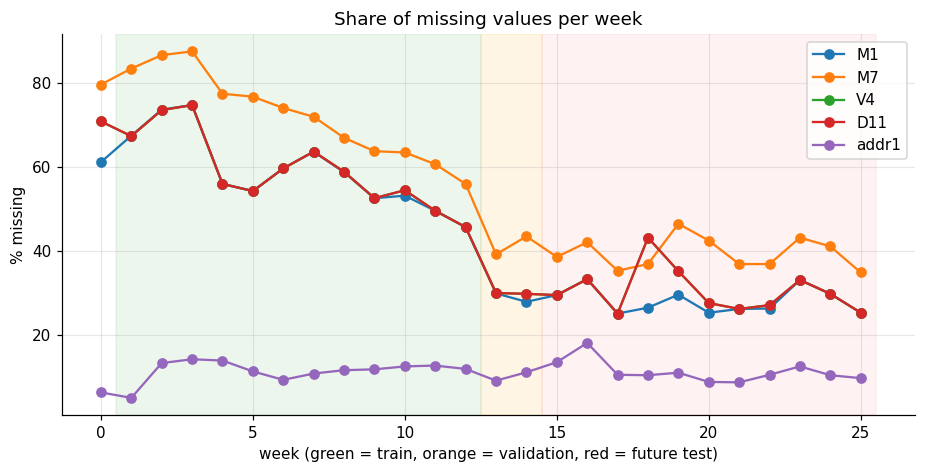


column                 period  missing_%  fraud_%_if_missing  fraud_%_if_present
    M1  1 train early (wk1-6)       66.0                3.56                1.69
    M1  2 train late (wk7-12)       53.8                5.80                2.18
    M1 3 validation (wk13-14)       29.0                6.38                2.03
    M1 4 test early (wk15-19)       28.7                8.56                2.12
    M1  5 test late (wk20-25)       27.8                7.36                1.93
    M7  1 train early (wk1-6)       82.1                3.26                1.37
    M7  2 train late (wk7-12)       63.7                5.24                2.18
    M7 3 validation (wk13-14)       41.1                5.10                2.02
    M7 4 test early (wk15-19)       39.7                6.72                2.17
    M7  5 test late (wk20-25)       39.3                5.75                1.94
    V4  1 train early (wk1-6)       66.0                3.56                1.69
    V4  2 train late (wk7-1

In [10]:
# 1) share of missing values per week (V4 and D11 lie exactly on top of each other; addr1 is the stable control)
check = ["M1", "M7", "V4", "D11", "addr1"]
weekly_missing = pd.DataFrame({c: df[c].isna().groupby(df["week"]).mean() * 100 for c in check}).round(1)
print(weekly_missing.T.to_string())
ax = weekly_missing.plot(figsize=(10, 4.5), marker="o")
ax.axvspan(0.5, 12.5, color="green", alpha=0.07); ax.axvspan(12.5, 14.5, color="orange", alpha=0.10); ax.axvspan(14.5, 25.5, color="red", alpha=0.05)
ax.set_xlabel("week (green = train, orange = validation, red = future test)"); ax.set_ylabel("% missing")
ax.set_title("Share of missing values per week"); plt.show()

# 2) fraud rate when missing vs present, by period
periods = {"1 train early (wk1-6)": (1, 6), "2 train late (wk7-12)": (7, 12), "3 validation (wk13-14)": (13, 14),
           "4 test early (wk15-19)": (15, 19), "5 test late (wk20-25)": (20, 25)}
rows = []
for c in ["M1", "M7", "V4", "D11", "addr1"]:
    is_miss = df[c].isna()
    for name, (a, b) in periods.items():
        m = df["week"].between(a, b)
        rows.append({"column": c, "period": name, "missing_%": round(is_miss[m].mean() * 100, 1),
                     "fraud_%_if_missing": round(df.loc[m & is_miss, "isFraud"].mean() * 100, 2),
                     "fraud_%_if_present": round(df.loc[m & ~is_miss, "isFraud"].mean() * 100, 2)})
print()
print(pd.DataFrame(rows).to_string(index=False))

# 3) where does the first model lose accuracy? (V4 missing vs present, early vs late test weeks)
test_df["V4_missing"] = df.loc[test_mask, "V4"].isna().values
test_df["period"] = np.where(test_df.week <= 19, "early (wk15-19)", "late (wk20-25)")
rows = []
for (flag, per), g in test_df.groupby(["V4_missing", "period"]):
    pr = average_precision_score(g.y, g.score)
    rows.append({"V4": "missing" if flag else "present", "period": per, "rows": len(g), "frauds": int(g.y.sum()),
                 "fraud_rate_%": round(g.y.mean() * 100, 2), "PR_AUC": round(pr, 3), "lift_vs_random": round(pr / g.y.mean(), 1)})
print("\nModel quality by V4 group (lift = PR-AUC divided by the fraud rate)")
print(pd.DataFrame(rows).to_string(index=False))

**Cross-check with two more measures.** PSI includes a "missing" bin. **KS** (largest gap between two distributions) and **Wasserstein** (how far values must move) compare only the values that exist, so they show whether the *values* changed. Each also gets a noise floor.

## Cross-checking drift with KS and Wasserstein distances

I use two additional distributional measures to check the PSI results for numeric features. The Kolmogorov–Smirnov (KS) statistic measures the largest difference between the two empirical distribution functions, while the Wasserstein distance measures how far the observed values would need to move to match the reference distribution. Both calculations ignore missing observations, so they focus on changes in the values themselves. I scale the Wasserstein distance by the feature's interquartile range and use training-week comparisons to estimate a 95th-percentile noise floor for each measure. I then compare the three drift rankings, their top-20 overlap, and the missingness shift for features flagged by PSI.


In [11]:
rng = np.random.RandomState(0)
num_feats = [c for c in feature_cols if c not in text_cols]
tr_idx, te_idx = np.where(train_mask)[0], np.where(test_mask)[0]
tr_wk, te_wk = week[tr_idx], week[te_idx]
Xtr = X.iloc[tr_idx][num_feats].values
Xte = X.iloc[te_idx][num_feats].values

def ks_wd(ref, cur, scale):
    """KS statistic and (scaled) Wasserstein distance between two samples, ignoring missing values."""
    r, c = ref[~np.isnan(ref)], cur[~np.isnan(cur)]
    if len(r) < 50 or len(c) < 50 or not scale > 0:
        return np.nan, np.nan
    if len(r) > 50_000: r = rng.choice(r, 50_000, replace=False)
    if len(c) > 50_000: c = rng.choice(c, 50_000, replace=False)
    return ks_2samp(r, c).statistic, wasserstein_distance(r, c) / scale

rows = []
for j, f in enumerate(num_feats):
    a = Xtr[:, j]
    nn = a[~np.isnan(a)]
    if len(nn) < 50:
        continue
    scale = np.subtract(*np.quantile(nn, [0.75, 0.25]))                 # typical spread of the feature
    if scale <= 0:
        scale = nn.std()
    drift = [ks_wd(a, Xte[te_wk == w, j], scale) for w in test_weeks]
    noise = [ks_wd(a[tr_wk != w], a[tr_wk == w], scale) for w in train_weeks]
    rows.append({"feature": f, "ks": np.nanmean([d[0] for d in drift]), "wd": np.nanmean([d[1] for d in drift]),
                 "ks_noise": np.nanquantile([n[0] for n in noise], 0.95), "wd_noise": np.nanquantile([n[1] for n in noise], 0.95)})
ks_table = pd.DataFrame(rows).set_index("feature")
ks_table["ks_excess"] = (ks_table.ks - ks_table.ks_noise).clip(lower=0)
ks_table["wd_excess"] = (ks_table.wd - ks_table.wd_noise).clip(lower=0)
del Xtr, Xte

drift_cmp = res.set_index("feature")[["family", "psi_future", "excess"]].rename(columns={"excess": "psi_excess"}).join(ks_table, how="inner")
drift_cmp["missing_shift_pp"] = (X.loc[test_mask, drift_cmp.index].isna().mean() - X.loc[train_mask, drift_cmp.index].isna().mean()) * 100

show = ["family", "psi_excess", "ks", "ks_excess", "wd_excess", "missing_shift_pp"]
for title, col in [("PSI excess (includes the missing bin)", "psi_excess"), ("KS excess (values only)", "ks_excess"), ("Wasserstein excess", "wd_excess")]:
    print(f"Top 12 by {title}:")
    print(drift_cmp.sort_values(col, ascending=False)[show].head(12).round(3).to_string(), "\n")

print("Agreement between the three rankings (Spearman over", len(drift_cmp), "features):")
print(drift_cmp[["psi_excess", "ks_excess", "wd_excess"]].corr(method="spearman").round(2).to_string())
top20 = lambda col: set(drift_cmp[col].nlargest(20).index)
print("Top-20 overlap  PSI-KS:", len(top20("psi_excess") & top20("ks_excess")), "| PSI-Wasserstein:", len(top20("psi_excess") & top20("wd_excess")),
      "| KS-Wasserstein:", len(top20("ks_excess") & top20("wd_excess")))
flag = (drift_cmp.psi_future > 0.25) & (drift_cmp.psi_excess > 0)
print("\nThe", int(flag.sum()), "PSI-flagged features vs the others (median):")
print(drift_cmp.groupby(flag)[["ks_excess", "wd_excess", "missing_shift_pp"]].median().round(3).rename(index={True: "PSI-flagged", False: "others"}).to_string())

Top 12 by PSI excess (includes the missing bin):
        family  psi_excess     ks  ks_excess  wd_excess  missing_shift_pp
feature                                                                  
D11          D       0.314  0.093      0.043      0.086           -30.376
V4           V       0.286  0.020      0.000      0.000           -30.376
V5           V       0.286  0.018      0.000      0.000           -30.376
V8           V       0.286  0.008      0.000      0.000           -30.376
V9           V       0.286  0.009      0.000      0.000           -30.376
V2           V       0.286  0.013      0.000      0.010           -30.376
V7           V       0.286  0.014      0.004      0.022           -30.376
V3           V       0.286  0.017      0.004      0.017           -30.376
V6           V       0.286  0.011      0.001      0.007           -30.376
V10          V       0.283  0.020      0.000      0.000           -30.376
C12          C       0.025  0.084      0.030      0.000        

## Evaluating model-retraining strategies

I define a function that trains a model for a given future week using only data available before that week. The function also supports a rolling training window and stores fitted models in a cache to avoid repeating the same training. I use it to generate predictions under four strategies: a single frozen model, retraining every four weeks, retraining every two weeks, and retraining every two weeks with an eight-week rolling window. I then compare their weekly and overall PR-AUC values, along with the share of frauds caught when only the top 5% of transactions can be reviewed. The summary also records how many retraining events each strategy requires and its improvement over the static model.


In [12]:
model_cache = {} if TRAIN_FROM_SCRATCH else dict(B["model_cache"])      # (week, window) -> trained model

def train_for(r, window=None):
    """The model retrained at week r, using only data from BEFORE week r (trains it if not stored yet)."""
    key = (r, window)
    if key not in model_cache:
        lo = 1 if window is None else max(1, r - 2 - window)
        tr, va = (week >= lo) & (week <= r - 3), np.isin(week, [r - 2, r - 1])
        t0 = time.time()
        m = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=42)
        m.fit(X[tr], y[tr], eval_set=[(X[va], y[va])], callbacks=[lgb.early_stopping(30, verbose=False)])
        print(f"  trained for week {r} | window={window} | train weeks {lo}-{r-3} | rows={tr.sum():,} | {round(time.time()-t0)}s")
        model_cache[key] = m
    return model_cache[key]

def run_strategy(every, window=None):
    """Fraud scores for all future rows when retraining every `every` weeks."""
    out = np.full(len(df), np.nan)
    for w in test_weeks:
        r = 15 + ((w - 15) // every) * every                    # most recent retraining point
        idx = np.where(week == w)[0]
        out[idx] = train_for(r, window).predict_proba(X.iloc[idx])[:, 1]
    return out

strategies = {"static":              dict(every=99, window=None),
              "every 4 weeks":       dict(every=4,  window=None),
              "every 2 weeks":       dict(every=2,  window=None),
              "rolling 8w, every 2": dict(every=2,  window=8)}
strategy_scores = {name: run_strategy(**kw) for name, kw in strategies.items()}
n_retrains = {name: len({15 + ((w - 15) // kw["every"]) * kw["every"] for w in test_weeks}) for name, kw in strategies.items()}

def recall_at_budget(s, weeks, frac):
    """Share of all frauds caught if only the top `frac` highest-scored transactions of each week are reviewed."""
    caught = total = 0
    for w in weeks:
        idx = np.where(week == w)[0]
        top = np.argsort(-s[idx])[:int(round(frac * len(idx)))]
        caught += y[idx][top].sum(); total += y[idx].sum()
    return caught / total

def summarize(names):
    t = pd.DataFrame({
        "retrains":             {n: n_retrains[n] for n in names},
        "PR-AUC all weeks":     {n: avg(strategy_scores[n], test_weeks) for n in names},
        "PR-AUC weeks 15-17":   {n: avg(strategy_scores[n], [15, 16, 17]) for n in names},
        "PR-AUC weeks 23-25":   {n: avg(strategy_scores[n], [23, 24, 25]) for n in names},
        "recall top 5% (all)":  {n: recall_at_budget(strategy_scores[n], test_weeks, 0.05) for n in names},
        "recall top 5% (late)": {n: recall_at_budget(strategy_scores[n], [23, 24, 25], 0.05) for n in names}})
    t["gain vs static %"] = ((t["PR-AUC all weeks"] / t.loc["static", "PR-AUC all weeks"] - 1) * 100).round(1)
    return t

per_week = pd.DataFrame({n: {w: avg(s, [w]) for w in test_weeks} for n, s in strategy_scores.items()})
print("PR-AUC per future week"); print(per_week.round(3).to_string())
print("\nSummary"); print(summarize(list(strategies)).round(3).to_string())

PR-AUC per future week
    static  every 4 weeks  every 2 weeks  rolling 8w, every 2
15   0.561          0.561          0.561                0.548
16   0.597          0.597          0.597                0.576
17   0.624          0.624          0.649                0.646
18   0.492          0.492          0.496                0.511
19   0.474          0.527          0.527                0.548
20   0.392          0.455          0.455                0.452
21   0.483          0.564          0.597                0.575
22   0.432          0.460          0.514                0.526
23   0.427          0.514          0.514                0.536
24   0.499          0.563          0.563                0.544
25   0.475          0.570          0.594                0.591

Summary
                     retrains  PR-AUC all weeks  PR-AUC weeks 15-17  PR-AUC weeks 23-25  recall top 5% (all)  recall top 5% (late)  gain vs static %
static                      1             0.505               0.594        

## Checking whether retraining gains are larger than sampling variation

I use bootstrap resampling of future transactions to estimate the difference in PR-AUC between each retraining strategy and the static model. I repeat the comparison for the full future-test period and for the late weeks (23–25), where deterioration is most relevant. For every resample, I calculate the difference using the same sampled transaction indices for both strategies. I report the mean gain and its 95% bootstrap interval, and also count how many individual future weeks show a higher PR-AUC than the static model. As a further comparison, I calculate the difference between retraining every two weeks and every four weeks.


In [13]:
# are the gains over the static model more than luck? (bootstrap on future transactions)
rng = np.random.RandomState(0)
rows_test = np.where(tw)[0]
late_rows = np.where(np.isin(week, [23, 24, 25]))[0]

def boot_diff(rows, name, other="static", n=100):
    diffs = []
    for _ in range(n):
        i = rng.choice(rows, len(rows), replace=True)
        if y[i].sum() == 0:
            continue
        diffs.append(average_precision_score(y[i], strategy_scores[name][i]) - average_precision_score(y[i], strategy_scores[other][i]))
    return np.mean(diffs), np.quantile(diffs, 0.025), np.quantile(diffs, 0.975)

out = []
for name in ["every 4 weeks", "every 2 weeks", "rolling 8w, every 2"]:
    m_all, lo_all, hi_all = boot_diff(rows_test, name)
    m_late, lo_late, hi_late = boot_diff(late_rows, name)
    out.append({"strategy": name, "weeks better than static": f"{(per_week[name] > per_week['static']).sum()}/{len(test_weeks)}",
                "gain, all weeks": round(m_all, 3), "95% range": f"{lo_all:.3f} to {hi_all:.3f}",
                "gain, weeks 23-25": round(m_late, 3), "95% range (late)": f"{lo_late:.3f} to {hi_late:.3f}"})
print(pd.DataFrame(out).to_string(index=False))
m4, lo4, hi4 = boot_diff(rows_test, "every 2 weeks", other="every 4 weeks")
print("\nevery 2 weeks minus every 4 weeks: %.3f  (95%% range %.3f to %.3f)" % (m4, lo4, hi4))

           strategy weeks better than static  gain, all weeks      95% range  gain, weeks 23-25 95% range (late)
      every 4 weeks                     7/11            0.040 0.036 to 0.044              0.084   0.072 to 0.096
      every 2 weeks                     9/11            0.051 0.047 to 0.055              0.092   0.081 to 0.105
rolling 8w, every 2                     9/11            0.047 0.040 to 0.055              0.088   0.074 to 0.102

every 2 weeks minus every 4 weeks: 0.010  (95% range 0.007 to 0.013)


## Evaluating alert thresholds and review capacity

I select an F1-maximising score threshold from the two validation weeks available to each retrained model. I apply that threshold to the corresponding future weeks and aggregate true positives, false positives, and false negatives. From these counts, I report precision, recall, F1, and the number of alerts per 1,000 transactions for the full future period and the late weeks. I also evaluate a fixed review-capacity setting by measuring how much fraud is captured when only the highest-scored 3% or 5% of transactions are reviewed. This gives a comparison of the strategies in terms of both classification quality and operational review volume.


In [14]:
def best_f1_threshold(yv, sv):
    p, r, t = precision_recall_curve(yv, sv)
    f1 = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
    return t[int(np.argmax(f1))]

thr_cache = {}
def threshold_for(r, window):
    if (r, window) not in thr_cache:
        va = np.isin(week, [r - 2, r - 1])
        thr_cache[(r, window)] = best_f1_threshold(y[va], model_cache[(r, window)].predict_proba(X[va])[:, 1])
    return thr_cache[(r, window)]

def threshold_metrics(name, kw, weeks):
    tp = fp = fn = n = 0
    for w in weeks:
        r = 15 + ((w - 15) // kw["every"]) * kw["every"]
        idx = np.where(week == w)[0]
        flag, yy = strategy_scores[name][idx] >= threshold_for(r, kw["window"]), y[idx]
        tp += int((flag & (yy == 1)).sum()); fp += int((flag & (yy == 0)).sum()); fn += int((~flag & (yy == 1)).sum()); n += len(idx)
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return {"precision": round(prec, 3), "recall": round(rec, 3), "F1": round(2 * prec * rec / max(prec + rec, 1e-12), 3),
            "alerts per 1000 txns": round(1000 * (tp + fp) / n, 1)}

for label, weeks in [("ALL FUTURE WEEKS (15-25)", test_weeks), ("LATE WEEKS (23-25)", [23, 24, 25])]:
    print(label)
    print(pd.DataFrame({n: threshold_metrics(n, kw, weeks) for n, kw in strategies.items()}).T.to_string(), "\n")

print("Share of fraud caught when only the top X% of each week's transactions can be reviewed")
print(pd.DataFrame({n: {"all weeks, top 3%": recall_at_budget(strategy_scores[n], test_weeks, 0.03),
                        "all weeks, top 5%": recall_at_budget(strategy_scores[n], test_weeks, 0.05),
                        "late weeks, top 3%": recall_at_budget(strategy_scores[n], [23, 24, 25], 0.03),
                        "late weeks, top 5%": recall_at_budget(strategy_scores[n], [23, 24, 25], 0.05)} for n in strategies}).T.round(3).to_string())

ALL FUTURE WEEKS (15-25)
                     precision  recall     F1  alerts per 1000 txns
static                   0.630   0.427  0.509                  25.0
every 4 weeks            0.640   0.462  0.537                  26.6
every 2 weeks            0.625   0.485  0.546                  28.6
rolling 8w, every 2      0.639   0.466  0.539                  26.9 

LATE WEEKS (23-25)
                     precision  recall     F1  alerts per 1000 txns
static                   0.592   0.407  0.482                  25.9
every 4 weeks            0.677   0.450  0.540                  25.0
every 2 weeks            0.654   0.478  0.552                  27.5
rolling 8w, every 2      0.693   0.453  0.547                  24.6 

Share of fraud caught when only the top X% of each week's transactions can be reviewed
                     all weeks, top 3%  all weeks, top 5%  late weeks, top 3%  late weeks, top 5%
static                           0.454              0.544               0.432          

## Comparing score drift, feature drift, and predictive performance

I take the static model trained before the future period and identify its 20 most important features using gain-based importance. For each future week, I compare the distribution of the model's scores with the scores from its validation period and calculate the mean score. I also calculate the average excess PSI among the 20 important features, using the feature-specific noise floors estimated earlier. I place these drift measurements alongside weekly PR-AUC and its relative change from validation performance. Finally, I use Spearman correlations to measure whether score drift or important-feature drift is associated with the static model's weekly predictive performance.


In [15]:
m_static = model_cache[(15, None)]
val_rows = np.isin(week, [13, 14])
val_scores = m_static.predict_proba(X[val_rows])[:, 1]                 # the model's scores in its own validation weeks
val_pr = average_precision_score(y[val_rows], val_scores)
top20 = list(X.columns[np.argsort(-m_static.booster_.feature_importance(importance_type="gain"))[:20]])
noise_floor = dict(zip(res["feature"], res["noise_floor"]))
ref = X.loc[val_rows]
print("Top 5 features of the static model (by gain):", top20[:5])
print("Static model PR-AUC on its own validation weeks:", round(val_pr, 3), "\n")

rows = []
for w in test_weeks:
    idx = np.where(week == w)[0]
    s = strategy_scores["static"][idx]
    excess = [max(psi(ref[f].values, X.iloc[idx][f].values) - noise_floor[f], 0.0) for f in top20]
    pr = average_precision_score(y[idx], s)
    rows.append({"week": w, "score_PSI": round(psi(val_scores, s), 3), "mean_score": round(float(s.mean()), 3),
                 "feature_PSI_above_noise": round(float(np.mean(excess)), 3), "PR_AUC_static": round(pr, 3),
                 "relative_PR_AUC_drop": round(1 - pr / val_pr, 3)})
signals = pd.DataFrame(rows)
print("Mean score in validation weeks:", round(float(val_scores.mean()), 3))
print(signals.to_string(index=False))
for col in ["score_PSI", "feature_PSI_above_noise"]:
    r = spearmanr(signals[col], signals.PR_AUC_static)
    print(f"Spearman({col}, PR-AUC) = {r.correlation:.2f}  (p={r.pvalue:.3f}, n={len(signals)} weeks)")

Top 5 features of the static model (by gain): ['C7', 'C13', 'card2', 'V318', 'card1']
Static model PR-AUC on its own validation weeks: 0.528 

Mean score in validation weeks: 0.055
 week  score_PSI  mean_score  feature_PSI_above_noise  PR_AUC_static  relative_PR_AUC_drop
   15      0.005       0.058                    0.000          0.561                -0.063
   16      0.010       0.071                    0.001          0.597                -0.130
   17      0.019       0.054                    0.000          0.624                -0.182
   18      0.007       0.054                    0.001          0.492                 0.068
   19      0.015       0.050                    0.000          0.474                 0.103
   20      0.016       0.050                    0.000          0.392                 0.257
   21      0.020       0.052                    0.000          0.483                 0.086
   22      0.008       0.053                    0.005          0.432                 0.182


## Testing drift-triggered retraining

I define a strategy that monitors the most recently available labelled week and triggers retraining when its PR-AUC has fallen sufficiently below the model's own validation PR-AUC. A cooldown period prevents retraining too frequently, and a one-week lag ensures that the trigger uses a completed week rather than the week currently being scored. I repeat the experiment with three trigger levels: a 10%, 15%, and 25% performance drop. For each setting, I record the weeks in which retraining occurs, add its predictions to the existing strategy results, and compare the resulting performance and retraining count with the other strategies.


In [16]:
val_pr_cache = {}
def val_pr_of(r):
    """PR-AUC of the model retrained at week r on its own validation weeks."""
    if r not in val_pr_cache:
        va = np.isin(week, [r - 2, r - 1])
        val_pr_cache[r] = average_precision_score(y[va], model_cache[(r, None)].predict_proba(X[va])[:, 1])
    return val_pr_cache[r]

def run_triggered(thr, cooldown=2, lag=1):
    out = np.full(len(df), np.nan)
    r, retrain_weeks = 15, [15]
    for w in test_weeks:
        if w > 15 and (w - r) >= cooldown and (w - lag) >= r:
            idx = np.where(week == w - lag)[0]                               # the most recent week we can judge
            if 1 - average_precision_score(y[idx], out[idx]) / val_pr_of(r) > thr:
                r = w
                retrain_weeks.append(w)
        idx = np.where(week == w)[0]
        out[idx] = train_for(r, None).predict_proba(X.iloc[idx])[:, 1]
    return out, retrain_weeks

trigger_weeks = {}
for thr in [0.10, 0.15, 0.25]:
    name = f"trigger >{int(thr*100)}% drop"
    strategy_scores[name], trigger_weeks[name] = run_triggered(thr)
    n_retrains[name] = len(trigger_weeks[name])
    print(f"{name}: retrained at weeks {trigger_weeks[name]}")

summary2 = summarize(list(strategy_scores))
print()
print(summary2.round(3).to_string())

trigger >10% drop: retrained at weeks [15, 20, 23]
trigger >15% drop: retrained at weeks [15, 21, 24]
trigger >25% drop: retrained at weeks [15, 21]

                     retrains  PR-AUC all weeks  PR-AUC weeks 15-17  PR-AUC weeks 23-25  recall top 5% (all)  recall top 5% (late)  gain vs static %
static                      1             0.505               0.594               0.466                0.544                 0.519               0.0
every 4 weeks               3             0.545               0.594               0.550                0.581                 0.594               8.0
every 2 weeks               6             0.556               0.599               0.558                0.597                 0.605              10.1
rolling 8w, every 2         6             0.552               0.588               0.556                0.589                 0.600               9.3
trigger >10% drop           3             0.547               0.594               0.550                0.

## Accounting for a delay in fraud labels

I introduce a four-week label delay to represent the situation where fraud outcomes are not immediately available. The retraining function is modified so that, at week `r`, it uses only labels observed up to the period allowed by this delay. I then generate predictions for static, four-week, and two-week retraining schedules under this constraint. I compare their PR-AUC over all future weeks and the late weeks with the corresponding no-delay results, and I also report late-period recall under a 5% review budget. The final comparison shows how delayed feedback changes the benefit of more frequent retraining.


In [17]:
D = 4                                                                  # label delay in weeks
delay_cache = {} if TRAIN_FROM_SCRATCH else dict(B["delay_cache"])

def train_for_d(r):
    """The model retrained at week r when only labels up to week r-1-D are known."""
    key = (r, D)
    if key not in delay_cache:
        tr, va = (week >= 1) & (week <= r - 3 - D), np.isin(week, [r - 2 - D, r - 1 - D])
        m = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=42)
        m.fit(X[tr], y[tr], eval_set=[(X[va], y[va])], callbacks=[lgb.early_stopping(30, verbose=False)])
        print(f"  trained for week {r} | train weeks 1-{r-3-D} | rows={tr.sum():,}")
        delay_cache[key] = m
    return delay_cache[key]

def run_delayed(every):
    out = np.full(len(df), np.nan)
    for w in test_weeks:
        idx = np.where(week == w)[0]
        out[idx] = train_for_d(15 + ((w - 15) // every) * every).predict_proba(X.iloc[idx])[:, 1]
    return out

delayed = {name: run_delayed(every) for name, every in [("static", 99), ("every 4 weeks", 4), ("every 2 weeks", 2)]}

tab = pd.DataFrame({n: {"PR-AUC, no delay": avg(strategy_scores[n], test_weeks), f"PR-AUC, {D}w delay": avg(delayed[n], test_weeks),
                        "late PR-AUC, no delay": avg(strategy_scores[n], [23, 24, 25]), f"late PR-AUC, {D}w delay": avg(delayed[n], [23, 24, 25]),
                        f"recall top 5% late, {D}w delay": recall_at_budget(delayed[n], [23, 24, 25], 0.05)} for n in delayed}).T
print(tab.round(3).to_string())
print("\nGain over the static model (PR-AUC, all weeks):")
for n in ["every 4 weeks", "every 2 weeks"]:
    print(f"  {n}: no delay {tab.loc[n, 'PR-AUC, no delay'] - tab.loc['static', 'PR-AUC, no delay']:+.3f} | "
          f"{D}w delay {tab.loc[n, f'PR-AUC, {D}w delay'] - tab.loc['static', f'PR-AUC, {D}w delay']:+.3f}")

               PR-AUC, no delay  PR-AUC, 4w delay  late PR-AUC, no delay  late PR-AUC, 4w delay  recall top 5% late, 4w delay
static                    0.505             0.454                  0.466                  0.427                         0.472
every 4 weeks             0.545             0.482                  0.550                  0.501                         0.539
every 2 weeks             0.556             0.488                  0.558                  0.511                         0.549

Gain over the static model (PR-AUC, all weeks):
  every 4 weeks: no delay +0.041 | 4w delay +0.027
  every 2 weeks: no delay +0.051 | 4w delay +0.034


## Comparing strategies using estimated operational costs

I define four cost scenarios that assign different penalties to false-positive alerts and missed frauds. The cost of a false positive can include a fixed review cost and, in one scenario, a percentage of the transaction amount; the cost of a missed fraud depends on the amount and a scenario-specific fixed penalty. For each model and scenario, I choose the cost-minimising threshold using that model's labelled validation weeks. I apply the selected threshold to each future week and add the costs of false positives and false negatives. I compare the total cost with the static-model and no-model baselines, calculate percentage savings, and estimate the break-even amount that could be spent on each additional retraining event.


In [18]:
scenarios = {"cheap review":   dict(fp_fixed=2,  fp_pct=0.00, fn_pct=1.0, fn_fixed=0),
             "balanced":       dict(fp_fixed=10, fp_pct=0.00, fn_pct=1.0, fn_fixed=15),
             "friction-heavy": dict(fp_fixed=25, fp_pct=0.02, fn_pct=1.0, fn_fixed=15),
             "fraud-heavy":    dict(fp_fixed=5,  fp_pct=0.00, fn_pct=2.0, fn_fixed=25)}

def cost_vectors(yy, aa, sc):
    fp = (1 - yy) * (sc["fp_fixed"] + sc["fp_pct"] * aa)               # cost if a legitimate transaction is flagged
    fn = yy * (sc["fn_pct"] * aa + sc["fn_fixed"])                     # cost if a fraud is missed
    return fp, fn

def best_cost_threshold(yv, sv, av, sc):
    """The score threshold with the lowest total cost on a labelled (validation) set."""
    o = np.argsort(-sv, kind="mergesort")
    fp, fn = cost_vectors(yv[o], av[o], sc)
    total_fn = fn.sum()
    cost = np.r_[total_fn, np.cumsum(fp) + (total_fn - np.cumsum(fn))]   # cost of flagging the top m transactions
    m = int(np.argmin(cost))
    return np.inf if m == 0 else sv[o][m - 1]

def model_key(name, w):
    """Which stored model produced the scores of strategy `name` in week w."""
    if name == "static":              return (15, None)
    if name == "every 4 weeks":       return (15 + ((w - 15) // 4) * 4, None)
    if name == "every 2 weeks":       return (15 + ((w - 15) // 2) * 2, None)
    if name == "rolling 8w, every 2": return (15 + ((w - 15) // 2) * 2, 8)
    return (max(x for x in trigger_weeks[name] if x <= w), None)        # drift-triggered strategies

thr_cost = {}
def cost_threshold(key, scname):
    if (key, scname) not in thr_cost:
        va = np.isin(week, [key[0] - 2, key[0] - 1])
        sv = model_cache[key].predict_proba(X[va])[:, 1]
        thr_cost[(key, scname)] = best_cost_threshold(y[va], sv, amt[va], scenarios[scname])
    return thr_cost[(key, scname)]

cost_names = list(strategy_scores)
total_cost, no_model = {n: {} for n in cost_names}, {}
for scname, sc in scenarios.items():
    no_model[scname] = cost_vectors(y[tw], amt[tw], sc)[1].sum()         # cost if nothing is ever flagged
    for n in cost_names:
        c = 0.0
        for w in test_weeks:
            idx = np.where(week == w)[0]
            flag = strategy_scores[n][idx] >= cost_threshold(model_key(n, w), scname)
            fp, fn = cost_vectors(y[idx], amt[idx], sc)
            c += fp[flag].sum() + fn[~flag].sum()
        total_cost[n][scname] = c
costs = pd.DataFrame(total_cost).T
costs.loc["(no model)"] = pd.Series(no_model)

print("Total cost over the future weeks ($)"); print(costs.round(0).astype(int).to_string())
sav = (1 - costs.loc[cost_names].div(costs.loc["static"], axis=1)) * 100
print("\nSaving vs the STATIC model (%)"); print(sav.round(1).to_string())
print("\nSaving of the static model vs having NO model (%)"); print(((1 - costs.loc["static"] / costs.loc["(no model)"]) * 100).round(1).to_string())

print("\nBreak-even cost per extra retrain, 'balanced' scenario:")
for n in cost_names[1:]:
    extra, saved = n_retrains[n] - 1, costs.loc["static", "balanced"] - costs.loc[n, "balanced"]
    if extra > 0:
        print(f"  {n:22s} saves ${saved:>9,.0f} with {extra} extra retrains -> break-even ${saved / extra:>8,.0f} per retrain")

Total cost over the future weeks ($)
                     cheap review  balanced  friction-heavy  fraud-heavy
static                     283697    676735          939306       667966
every 4 weeks              262632    594240          841082       608727
every 2 weeks              251879    559782          809154       583814
rolling 8w, every 2        275490    584908          829154       635280
trigger >10% drop          266577    610263          854599       621570
trigger >15% drop          266789    604233          856619       620712
trigger >25% drop          258565    604590          861620       607008
(no model)                1315109   1437794         1437794      2834692

Saving vs the STATIC model (%)
                     cheap review  balanced  friction-heavy  fraud-heavy
static                        0.0       0.0             0.0          0.0
every 4 weeks                 7.4      12.2            10.5          8.9
every 2 weeks                11.2      17.3            

## Measuring the stability of feature importance with SHAP values

I use SHAP contributions from the static LightGBM model to measure the average absolute contribution of each feature. I calculate these importance values for all sampled transactions and for fraud transactions separately across the training period, early test period, and late test period. I compare feature-importance rankings using Spearman correlation and top-20 overlap, and I calculate the share of total importance contributed by each feature family. I also compare the static model with a model retrained near the end of the test period, evaluating both models on the same late-period transactions. This last comparison isolates changes in the explanations associated with retraining from changes caused by evaluating on different transactions.


In [19]:
rng = np.random.RandomState(0)
m_static = model_cache[(15, None)]       # trained once on weeks 1-12
m_late   = model_cache[(25, None)]       # retrained on weeks 1-22

def sample_rows(a, b, n=5000, fraud_only=False):
    mask = (week >= a) & (week <= b)
    if fraud_only:
        mask &= (y == 1)
    idx = np.where(mask)[0]
    return rng.choice(idx, min(n, len(idx)), replace=False)

def mean_abs_shap(model, idx):
    sv = model.booster_.predict(X.iloc[idx], pred_contrib=True)[:, :-1]      # last column is the baseline, not a feature
    return pd.Series(np.abs(sv).mean(axis=0), index=X.columns)

def stability(a, b, k=20):
    """(Spearman correlation over all features, overlap of the top-k features)."""
    ta, tb = set(a.nlargest(k).index), set(b.nlargest(k).index)
    return round(spearmanr(a, b).correlation, 3), round(len(ta & tb) / len(ta | tb), 3)

periods_s = {"train (wk 1-12)": (1, 12), "test early (wk 15-17)": (15, 17), "test late (wk 23-25)": (23, 25)}
imp_all   = pd.DataFrame({n: mean_abs_shap(m_static, sample_rows(a, b)) for n, (a, b) in periods_s.items()})
imp_fraud = pd.DataFrame({n: mean_abs_shap(m_static, sample_rows(a, b, 2000, True)) for n, (a, b) in periods_s.items()})

share = imp_all / imp_all.sum() * 100
top = imp_all["train (wk 1-12)"].nlargest(12).index
print("A1. Share of total importance (%), static model, all transactions")
print(share.loc[top].round(1).to_string())

base_b = mean_abs_shap(m_static, sample_rows(1, 12))                         # a second sample of the SAME period = noise baseline
rows = [{"comparison": "train vs train (noise baseline)", "all rows": stability(imp_all["train (wk 1-12)"], base_b), "fraud rows": "-"}]
for n in ["test early (wk 15-17)", "test late (wk 23-25)"]:
    rows.append({"comparison": f"train vs {n}", "all rows": stability(imp_all["train (wk 1-12)"], imp_all[n]),
                 "fraud rows": stability(imp_fraud["train (wk 1-12)"], imp_fraud[n])})
print("\nA2. Stability as (Spearman over all features, top-20 overlap)")
print(pd.DataFrame(rows).to_string(index=False))

print("\nA3. Share of importance by feature family (%)")
print(share.groupby(share.index.map(family)).sum().round(1).to_string())

late_idx = sample_rows(23, 25)
s_static, s_late = mean_abs_shap(m_static, late_idx), mean_abs_shap(m_late, late_idx)
shift = (s_late / s_late.sum() - s_static / s_static.sum()) * 100
print("\nB. Static vs retrained model on the same late rows (Spearman, top-20 overlap):", stability(s_static, s_late))
print("Relies on MORE (change in importance share, % points):"); print(shift.nlargest(6).round(2).to_string())
print("Relies on LESS:"); print(shift.nsmallest(6).round(2).to_string())

A1. Share of total importance (%), static model, all transactions
                train (wk 1-12)  test early (wk 15-17)  test late (wk 23-25)
TransactionAmt              4.8                    4.7                   4.5
C13                         4.7                    4.7                   4.9
card1                       2.9                    3.0                   2.9
card2                       2.9                    3.0                   2.9
V90                         2.6                    2.9                   2.7
card6                       2.5                    2.5                   2.4
P_emaildomain               2.5                    2.4                   2.3
M4                          2.4                    2.3                   2.3
ProductCD                   2.4                    1.6                   1.7
C1                          2.3                    2.2                   2.0
D2                          2.2                    2.3                   2.4
addr1     

## Checking SHAP direction and random-seed variation

I examine whether the direction of the relationship between a feature's value and its SHAP contribution remains similar across the training, early-test, and late-test periods. I focus on the ten features with the highest importance in the training period and calculate Spearman correlations between their observed values and their corresponding SHAP contributions. I then fit another static LightGBM model on the same training data but with a different random seed. By comparing its SHAP importance with the original static model and with the retrained model, I assess whether the observed explanation changes are larger than the variation introduced by model randomness alone.


In [20]:
# ---- Check A: direction of the effect (does a higher value still push toward fraud?) ----
top_feats = list(imp_all["train (wk 1-12)"].nlargest(10).index)
col_index = {c: j for j, c in enumerate(X.columns)}
rows = []
for n, (a, b) in periods_s.items():
    idx = sample_rows(a, b, 4000)
    sv = m_static.booster_.predict(X.iloc[idx], pred_contrib=True)[:, :-1]
    for f in top_feats:
        xv = X[f].values[idx]; ok = ~np.isnan(xv)
        rows.append({"feature": f, "period": n, "direction": spearmanr(xv[ok], sv[ok, col_index[f]]).correlation})
dirs = pd.DataFrame(rows).pivot(index="feature", columns="period", values="direction")[list(periods_s)]
print("Spearman(feature value, SHAP value): + means a higher value -> more fraud-like")
print("(for text-coded columns the sign has no direct meaning; only stability does)")
print(dirs.loc[top_feats].round(2).to_string())

# ---- Check B: how much does the explanation change from a different random seed alone? ----
tr15, va15 = (week >= 1) & (week <= 12), np.isin(week, [13, 14])
m_seed = lgb.LGBMClassifier(**LGBM_PARAMS, random_state=7)
m_seed.fit(X[tr15], y[tr15], eval_set=[(X[va15], y[va15])], callbacks=[lgb.early_stopping(30, verbose=False)])
s_seed = mean_abs_shap(m_seed, late_idx)
shift_seed = (s_seed / s_seed.sum() - s_static / s_static.sum()) * 100
print("\nStatic vs SAME-DATA model with a different seed:", stability(s_static, s_seed))
print("Static vs RETRAINED model:                      ", stability(s_static, s_late))
print("\nLargest changes caused by the seed alone (% points):");  print(shift_seed.reindex(shift_seed.abs().nlargest(6).index).round(2).to_string())
print("Largest changes caused by retraining (% points):");        print(shift.reindex(shift.abs().nlargest(6).index).round(2).to_string())

Spearman(feature value, SHAP value): + means a higher value -> more fraud-like
(for text-coded columns the sign has no direct meaning; only stability does)
period          train (wk 1-12)  test early (wk 15-17)  test late (wk 23-25)
feature                                                                     
TransactionAmt             0.91                   0.90                  0.89
C13                       -0.92                  -0.92                 -0.93
card1                     -0.41                  -0.36                 -0.35
card2                      0.15                   0.24                  0.21
V90                       -0.82                  -0.83                 -0.83
card6                     -0.77                  -0.70                 -0.76
P_emaildomain             -0.83                  -0.83                 -0.80
M4                        -0.36                  -0.30                 -0.38
ProductCD                  0.09                   0.10                  0.

## Saving the main figures and result tables

I create the report output directory and define a helper function that saves each figure as a PNG before displaying it. I generate the main figures for the random-versus-time split comparison, weekly performance of the frozen models, retraining strategies, missingness over time, and estimated cost savings. I then export the principal result tables—including model performance, retraining performance, cost savings, drift measures, and seed variation—as CSV files. The final print statement lists the files written to the report directory.


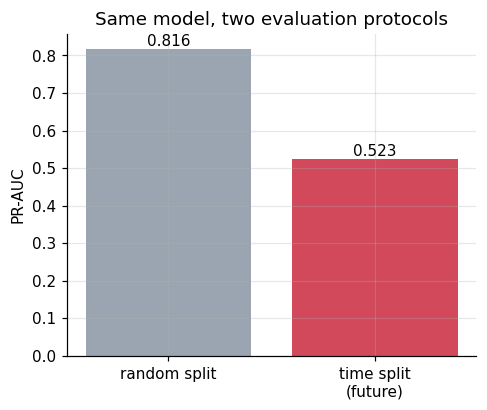

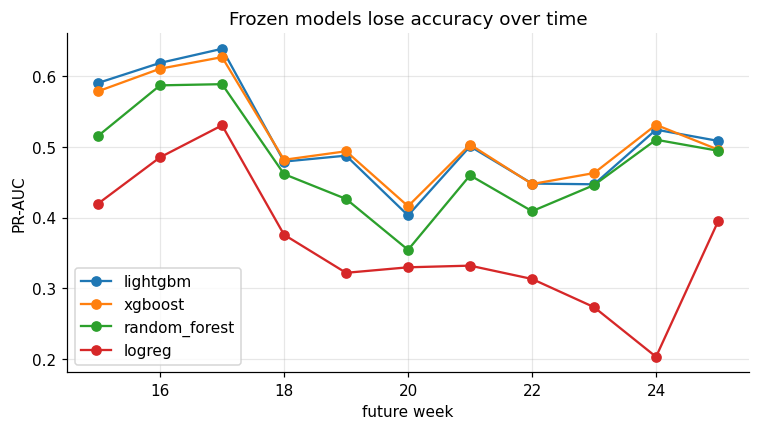

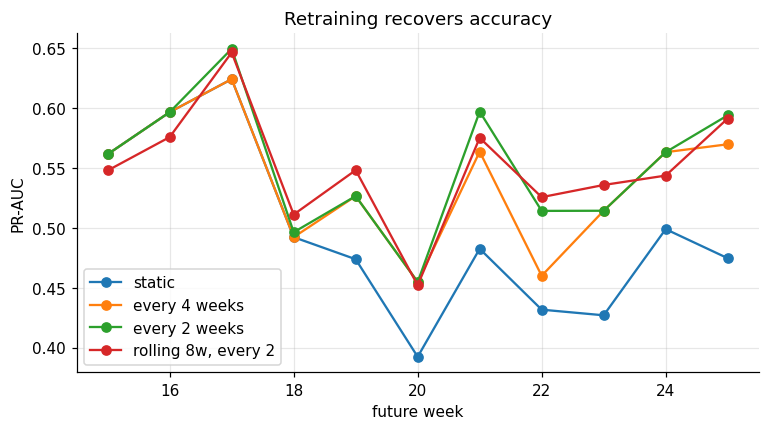

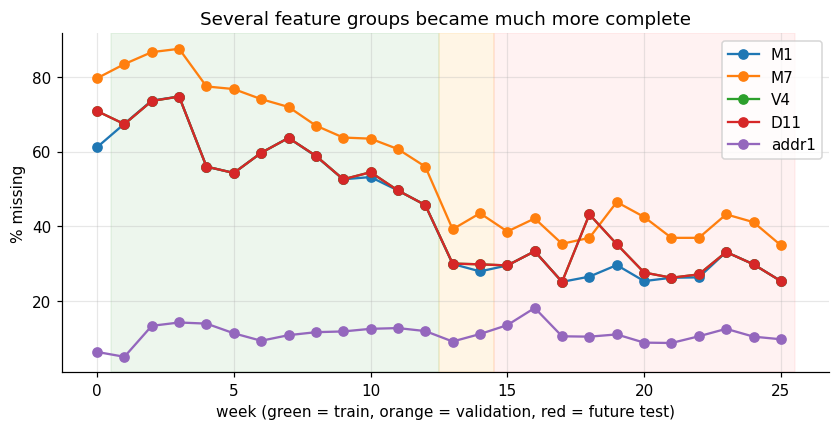

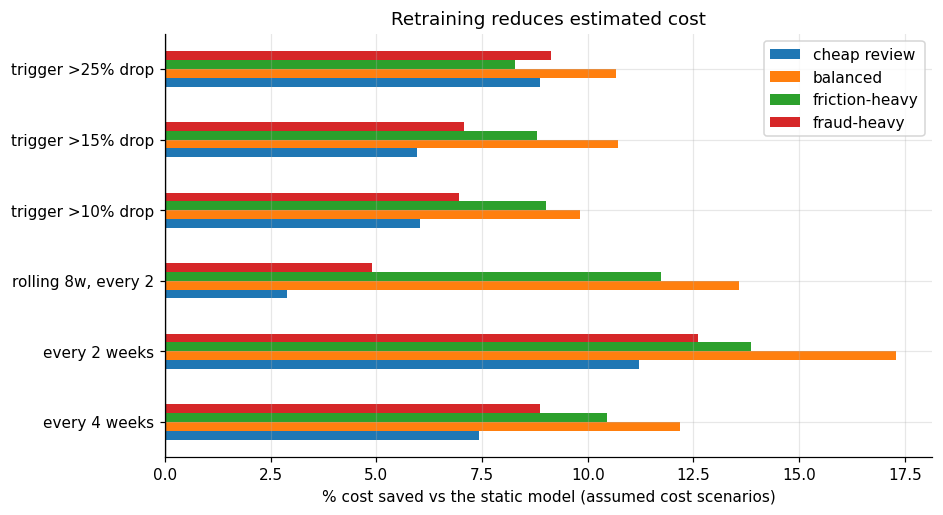

NameError: name 'seeds' is not defined

In [21]:
os.makedirs(REPORT_DIR, exist_ok=True)

def save_show(name):
    plt.savefig(f"{REPORT_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Figure 1: random split vs time split
fig, ax = plt.subplots(figsize=(4.8, 3.8))
ax.bar(["random split", "time split\n(future)"], [pr_random, pr_future], color=["#9aa5b1", "#d1495b"])
for i, v in enumerate([pr_random, pr_future]):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center")
ax.set_ylabel("PR-AUC"); ax.set_title("Same model, two evaluation protocols")
save_show("fig1_random_vs_time_split")

# Figure 2: weekly PR-AUC of the four frozen models
wk_tbl = pd.DataFrame({n: [average_precision_score(y_test[wk_t == w], s[wk_t == w]) for w in test_weeks] for n, s in scores.items()}, index=test_weeks)
ax = wk_tbl.plot(marker="o", figsize=(8, 4)); ax.set_xlabel("future week"); ax.set_ylabel("PR-AUC"); ax.set_title("Frozen models lose accuracy over time")
save_show("fig2_baseline_models_by_week")

# Figure 3: weekly PR-AUC by retraining strategy
ax = per_week.plot(marker="o", figsize=(8, 4)); ax.set_xlabel("future week"); ax.set_ylabel("PR-AUC"); ax.set_title("Retraining recovers accuracy")
save_show("fig3_retraining_strategies_by_week")

# Figure 4: share of missing values over time
ax = weekly_missing.plot(marker="o", figsize=(9, 4))
ax.axvspan(0.5, 12.5, color="green", alpha=0.07); ax.axvspan(12.5, 14.5, color="orange", alpha=0.10); ax.axvspan(14.5, 25.5, color="red", alpha=0.05)
ax.set_xlabel("week (green = train, orange = validation, red = future test)"); ax.set_ylabel("% missing"); ax.set_title("Several feature groups became much more complete")
save_show("fig4_missing_share_over_time")

# Figure 5: cost saving vs static
ax = sav.drop("static").plot.barh(figsize=(9, 5)); ax.axvline(0, color="k")
ax.set_xlabel("% cost saved vs the static model (assumed cost scenarios)"); ax.set_title("Retraining reduces estimated cost")
save_show("fig5_cost_saving_vs_static")

# tables as CSV files
tables = {"table_baseline_models": base, "table_retraining_strategies": summary2, "table_cost_saving_vs_static": sav,
          "table_drift_measures": drift_cmp, "table_seed_variation": seeds}
for name, t in tables.items():
    if t is not None:
        t.to_csv(f"{REPORT_DIR}/{name}.csv")
print("Saved in", REPORT_DIR, ":", sorted(os.listdir(REPORT_DIR)))

## Benchmarking conventional models and adding missingness indicators

I build a preprocessing pipeline for a second model comparison. Numeric variables are median-imputed, given missingness indicators, and transformed to an approximately normal scale; low-cardinality categorical variables are imputed and one-hot encoded. I fit the preprocessing steps on the training period and apply the same transformations to the future-test period. I then evaluate the existing baseline models alongside new Logistic Regression models, a ridge linear-probability model, Naive Bayes, and a shallow decision tree. The table reports ROC-AUC and PR-AUC for all future weeks, early weeks, and late weeks, including the early-to-late performance drop.


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, OneHotEncoder
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
import time

low_card = [c for c in text_cols if df[c].nunique() <= 30]
numeric  = [c for c in X.columns if c not in text_cols]

prep = ColumnTransformer([
    ("num", Pipeline([("fill", SimpleImputer(strategy="median", add_indicator=True)),   # adds "was missing" flags
                      ("scale", QuantileTransformer(n_quantiles=200, subsample=100_000,
                                                    output_distribution="normal", random_state=42))]), numeric),
    ("cat", Pipeline([("fill", SimpleImputer(strategy="constant", fill_value=-1)),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20))]), low_card),
], sparse_threshold=0)

t0 = time.time()
Xtr_t = prep.fit_transform(X[train_mask]).astype("float32")
Xte_t = prep.transform(X[test_mask]).astype("float32")
ytr, y_t, wk_t = y[train_mask], y[test_mask], week[test_mask]
print("transformed shape:", Xtr_t.shape, "|", round(time.time() - t0), "s")

early, late = np.isin(wk_t, [15, 16, 17]), np.isin(wk_t, [23, 24, 25])
def report(name, s):
    return {"model": name,
            "ROC-AUC": roc_auc_score(y_t, s),
            "PR-AUC all": average_precision_score(y_t, s),
            "PR-AUC early": average_precision_score(y_t[early], s[early]),
            "PR-AUC late": average_precision_score(y_t[late], s[late])}

rows = [report(n, scores[n]) for n in ["logreg", "random_forest", "xgboost", "lightgbm"]]
rows[0]["model"] = "logreg (old: no missing flags)"

new_scores = {}
for C in [0.1, 0.01]:
    t0 = time.time()
    m = LogisticRegression(C=C, max_iter=1000, class_weight="balanced").fit(Xtr_t, ytr)
    new_scores[f"logreg + flags, C={C}"] = m.predict_proba(Xte_t)[:, 1]
    print(f"logreg C={C} done:", round(time.time() - t0), "s | iterations used:", int(m.n_iter_[0]))

new_scores["linear probability (Ridge)"] = Ridge(alpha=10).fit(Xtr_t, ytr).predict(Xte_t)
new_scores["naive Bayes"] = GaussianNB().fit(Xtr_t, ytr).predict_proba(Xte_t)[:, 1]
new_scores["decision tree (depth 6)"] = DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight="balanced",
                                                               random_state=42).fit(Xtr_t, ytr).predict_proba(Xte_t)[:, 1]
for n, s in new_scores.items():
    rows.append(report(n, s))

tab = pd.DataFrame(rows).set_index("model")
tab["drop (early-late)"] = tab["PR-AUC early"] - tab["PR-AUC late"]
print()
print(tab.round(3).to_string())

transformed shape: (292338, 376) | 26 s
logreg C=0.1 done: 172 s | iterations used: 1000
logreg C=0.01 done: 174 s | iterations used: 1000

                                ROC-AUC  PR-AUC all  PR-AUC early  PR-AUC late  drop (early-late)
model                                                                                            
logreg (old: no missing flags)    0.860       0.348         0.482        0.261              0.221
random_forest                     0.885       0.487         0.564        0.483              0.082
xgboost                           0.894       0.524         0.607        0.499              0.107
lightgbm                          0.894       0.523         0.617        0.493              0.124
logreg + flags, C=0.1             0.862       0.389         0.483        0.361              0.122
logreg + flags, C=0.01            0.862       0.392         0.483        0.368              0.115
linear probability (Ridge)        0.826       0.384         0.478        0.3

## Varying tree depth and regularisation strength

I extend the model comparison by fitting boosted-tree models at depths 1, 2, 3, and 6. This allows me to examine how predictive performance changes as the trees can represent more complex feature interactions. I also fit logistic-style linear models using stochastic gradient descent with L1, L2, and elastic-net penalties at two regularisation strengths. I evaluate each fitted model on the same future-test period using the shared reporting function, and record either the number of trees selected by early stopping or the number of non-zero coefficients. The final table compares overall performance and the difference between early- and late-period PR-AUC.


In [24]:
from sklearn.linear_model import SGDClassifier

rows = []

# ---------- A. boosted trees of increasing depth ----------
for depth in [1, 2, 3, 6]:
    t0 = time.time()
    m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.1, max_depth=depth,
                           num_leaves=2 if depth == 1 else 2 ** depth,
                           colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
                           scale_pos_weight=5, metric="average_precision",
                           random_state=42, verbose=-1)
    m.fit(X_train, y_train, eval_set=[(X_val, y_val)],
          callbacks=[lgb.early_stopping(30, verbose=False)])
    r = report(f"boosted trees, depth {depth}", m.predict_proba(X_test)[:, 1])
    r["detail"] = f"{m.best_iteration_} trees"
    rows.append(r)
    print(f"depth {depth} done: {round(time.time() - t0)} s")

# ---------- B. penalties for Logistic Regression ----------
for penalty, alpha in [("l2", 1e-5), ("l2", 1e-4), ("l1", 1e-5), ("l1", 1e-4),
                       ("elasticnet", 1e-5), ("elasticnet", 1e-4)]:
    t0 = time.time()
    clf = SGDClassifier(loss="log_loss", penalty=penalty, alpha=alpha, l1_ratio=0.5,
                        class_weight="balanced", max_iter=50, tol=1e-4, random_state=42)
    clf.fit(Xtr_t, ytr)
    r = report(f"logreg {penalty}, alpha={alpha:g}", clf.decision_function(Xte_t))
    r["detail"] = f"{int((clf.coef_ != 0).sum())} of {Xtr_t.shape[1]} coefficients non-zero"
    rows.append(r)
    print(f"{penalty} alpha={alpha:g} done: {round(time.time() - t0)} s")

tab2 = pd.DataFrame(rows).set_index("model")
tab2["relative drop %"] = ((tab2["PR-AUC early"] - tab2["PR-AUC late"]) / tab2["PR-AUC early"] * 100).round(0)
print()
print(tab2.round(3).to_string())

depth 1 done: 40 s
depth 2 done: 43 s
depth 3 done: 46 s
depth 6 done: 42 s
l2 alpha=1e-05 done: 23 s
l2 alpha=0.0001 done: 25 s
l1 alpha=1e-05 done: 55 s
l1 alpha=0.0001 done: 54 s
elasticnet alpha=1e-05 done: 56 s
elasticnet alpha=0.0001 done: 58 s

                                 ROC-AUC  PR-AUC all  PR-AUC early  PR-AUC late                            detail  relative drop %
model                                                                                                                             
boosted trees, depth 1             0.863       0.389         0.493        0.352                         400 trees             29.0
boosted trees, depth 2             0.881       0.471         0.559        0.454                         399 trees             19.0
boosted trees, depth 3             0.888       0.498         0.580        0.489                         383 trees             16.0
boosted trees, depth 6             0.888       0.508         0.593        0.475              

## Building hybrid models from tree-leaf features

I first fit a smaller boosted-tree model and record its performance as a reference. I then use the terminal leaf reached by each transaction in each tree as a categorical feature, converting these leaf assignments into a sparse one-hot matrix. In the first hybrid, I fit Logistic Regression using only the leaf indicators. In the second hybrid, I combine the leaf indicators with the scaled original features before fitting Logistic Regression. I compare both hybrid approaches with the original tree model using the same future-test metrics, including the early-to-late performance difference.


In [26]:
from scipy import sparse
from sklearn.preprocessing import OneHotEncoder

rows = []

# ---------- 1. small boosted-tree model that creates the "leaves" ----------
t0 = time.time()
gbm = lgb.LGBMClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, num_leaves=8,
                         colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
                         scale_pos_weight=5, metric="average_precision",
                         random_state=42, verbose=-1)
gbm.fit(X_train, y_train)
r = report("trees alone (depth 3, 100 trees)", gbm.predict_proba(X_test)[:, 1])
r["detail"] = "reference"
rows.append(r)

leaf_tr = gbm.predict(X_train, pred_leaf=True)         # which leaf of each tree every transaction falls into
leaf_te = gbm.predict(X_test,  pred_leaf=True)
enc = OneHotEncoder(handle_unknown="ignore")
L_tr = enc.fit_transform(leaf_tr)                      # sparse yes/no table: one column per leaf
L_te = enc.transform(leaf_te)
print("leaf features:", L_tr.shape, "|", round(time.time() - t0), "s")

# ---------- 2. A: logistic regression on leaves only ----------
for C in [0.01, 0.1]:
    t0 = time.time()
    lr = LogisticRegression(C=C, max_iter=500, class_weight="balanced").fit(L_tr, ytr)
    r = report(f"hybrid A: logreg on leaves, C={C}", lr.predict_proba(L_te)[:, 1])
    r["detail"] = f"{int(lr.n_iter_[0])} iterations"
    rows.append(r)
    print(f"A, C={C} done: {round(time.time() - t0)} s")

# ---------- 3. B: leaves + the scaled original features ----------
t0 = time.time()
B_tr = sparse.hstack([L_tr, sparse.csr_matrix(Xtr_t)]).tocsr()
B_te = sparse.hstack([L_te, sparse.csr_matrix(Xte_t)]).tocsr()
lr = LogisticRegression(C=0.1, max_iter=500, class_weight="balanced").fit(B_tr, ytr)
r = report("hybrid B: logreg on leaves + features, C=0.1", lr.predict_proba(B_te)[:, 1])
r["detail"] = f"{int(lr.n_iter_[0])} iterations"
rows.append(r)
print(f"B done: {round(time.time() - t0)} s")

tab3 = pd.DataFrame(rows).set_index("model")
tab3["relative drop %"] = ((tab3["PR-AUC early"] - tab3["PR-AUC late"]) / tab3["PR-AUC early"] * 100).round(0)
print()
print(tab3.round(3).to_string())

leaf features: (292338, 787) | 20 s
A, C=0.01 done: 13 s
A, C=0.1 done: 32 s
B done: 218 s

                                              ROC-AUC  PR-AUC all  PR-AUC early  PR-AUC late          detail  relative drop %
model                                                                                                                        
trees alone (depth 3, 100 trees)                0.876       0.450         0.548        0.418       reference             24.0
hybrid A: logreg on leaves, C=0.01              0.869       0.464         0.547        0.445   89 iterations             19.0
hybrid A: logreg on leaves, C=0.1               0.860       0.455         0.538        0.437  234 iterations             19.0
hybrid B: logreg on leaves + features, C=0.1    0.861       0.462         0.539        0.449  500 iterations             17.0


## Modelling the weekly fraud rate with Poisson regression

I aggregate the data by week, calculating the number of transactions, the number of frauds, and the observed fraud rate. I use the log of weekly transaction volume as an exposure offset in Poisson regression so that the model describes the fraud rate rather than only the number of frauds. I compare a standard Poisson model, a quasi-Poisson fit with a dispersion adjustment, and a negative-binomial model to account for possible overdispersion. I then fit a model with an interaction between week and the `V4` missingness group to check whether the weekly fraud-rate trend differs when `V4` is missing. The plots compare observed weekly fraud rates with the fitted trend and show the two `V4` groups separately.


Weekly fraud RATE multiplier per extra week (1.000 = no trend):
  Poisson                : 1.0084  (95% CI 1.0065 to 1.0103, p=0.000)
  Poisson, quasi (robust): 1.0084  (95% CI 0.9972 to 1.0197, p=0.140)
  Negative binomial      : 1.0051  (95% CI 0.9942 to 1.0162, p=0.360)
Dispersion (Pearson chi2 / df): 34.78   | NB overdispersion alpha: 0.0362

Difference in weekly trend between the two groups (interaction): rate ratio 0.9629, p=0.000
  V4 missing  weekly rate multiplier: 1.0411  (95% CI 1.0266 to 1.0558, p=0.000)
  V4 present  weekly rate multiplier: 1.0025  (95% CI 0.9937 to 1.0113, p=0.584)


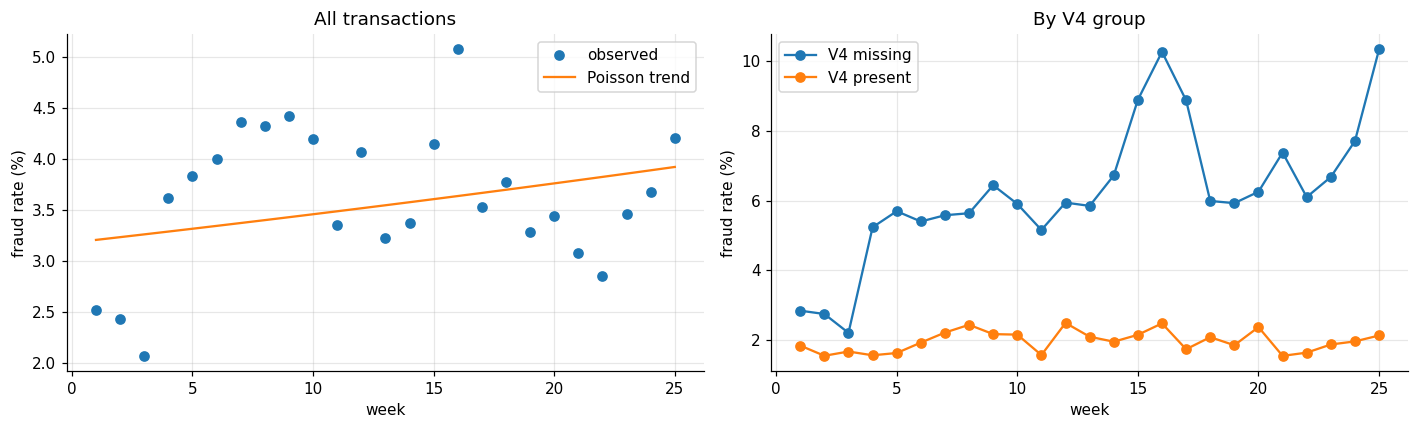

In [29]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# ---------- weekly counts (week 0 = warm-up, skipped) ----------
d = df[df["week"] >= 1]
wk = d.groupby("week")["isFraud"].agg(n="size", frauds="sum").reset_index()
wk["log_n"] = np.log(wk["n"])                      # "exposure": more transactions -> more frauds, all else equal
wk["rate_%"] = wk["frauds"] / wk["n"] * 100

# ---------- Model 1: Poisson regression, fraud rate with a time trend ----------
pois = smf.glm("frauds ~ week", data=wk, family=sm.families.Poisson(), offset=wk["log_n"]).fit()
dispersion = pois.pearson_chi2 / pois.df_resid     # about 1 = Poisson is fine; well above 1 = counts vary more than Poisson allows
quasi = smf.glm("frauds ~ week", data=wk, family=sm.families.Poisson(), offset=wk["log_n"]).fit(scale="X2")
nb = smf.negativebinomial("frauds ~ week", data=wk, offset=wk["log_n"]).fit(disp=0)

def rate_ratio(fit, name="week"):
    ci = np.exp(fit.conf_int().loc[name])
    return f"{np.exp(fit.params[name]):.4f}  (95% CI {ci[0]:.4f} to {ci[1]:.4f}, p={fit.pvalues[name]:.3f})"

print("Weekly fraud RATE multiplier per extra week (1.000 = no trend):")
print("  Poisson                :", rate_ratio(pois))
print("  Poisson, quasi (robust):", rate_ratio(quasi))
print("  Negative binomial      :", rate_ratio(nb))
print(f"Dispersion (Pearson chi2 / df): {dispersion:.2f}   | NB overdispersion alpha: {nb.params['alpha']:.4f}")

# ---------- Model 2: does the trend differ between V4 missing and V4 present? ----------
g = d.assign(grp=np.where(d["V4"].isna(), "V4 missing", "V4 present"))
gw = g.groupby(["week", "grp"])["isFraud"].agg(n="size", frauds="sum").reset_index()
gw["log_n"] = np.log(gw["n"])
joint = smf.glm("frauds ~ grp * week", data=gw, family=sm.families.Poisson(), offset=gw["log_n"]).fit(scale="X2")
inter = [k for k in joint.params.index if ":" in k][0]
print(f"\nDifference in weekly trend between the two groups (interaction): rate ratio {np.exp(joint.params[inter]):.4f}, p={joint.pvalues[inter]:.3f}")
for name, gg in gw.groupby("grp"):
    f = smf.glm("frauds ~ week", data=gg, family=sm.families.Poisson(), offset=gg["log_n"]).fit(scale="X2")
    print(f"  {name:11s} weekly rate multiplier:", rate_ratio(f))

# ---------- plot: observed weekly fraud rate vs the fitted trend ----------
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(wk["week"], wk["rate_%"], "o", label="observed")
ax[0].plot(wk["week"], pois.fittedvalues / wk["n"] * 100, "-", label="Poisson trend")
ax[0].set_xlabel("week"); ax[0].set_ylabel("fraud rate (%)"); ax[0].set_title("All transactions"); ax[0].legend()
for name, gg in gw.groupby("grp"):
    ax[1].plot(gg["week"], gg["frauds"] / gg["n"] * 100, "o-", label=name)
ax[1].set_xlabel("week"); ax[1].set_ylabel("fraud rate (%)"); ax[1].set_title("By V4 group"); ax[1].legend()
plt.tight_layout(); plt.show()

## Testing for level shifts at weeks 4 and 13

I extend the weekly count analysis by adding indicators for the periods beginning at weeks 4 and 13. I first model weekly fraud counts and legitimate-transaction counts without an exposure offset, which lets me examine changes in the two counts separately. I then include the log of transaction volume as an offset to estimate changes in the fraud rate for all transactions and for the two `V4` groups. I report exponentiated coefficients as rate or count multipliers with confidence intervals and p-values. The final plots show the weekly transaction and fraud counts, with reference lines at the two candidate change points.


Weekly number of FRAUDS ~ step at week 4 + week
   step4    multiplier 1.226  (95% CI 1.005 to 1.496, p=0.044)
   week     multiplier 0.986  (95% CI 0.977 to 0.995, p=0.003)
Weekly number of LEGITIMATE transactions ~ step at week 4 + week
   step4    multiplier 0.675  (95% CI 0.591 to 0.771, p=0.000)
   week     multiplier 0.994  (95% CI 0.988 to 1.001, p=0.102)

Fraud RATE, all transactions ~ step4 + step13 + week
   step4    multiplier 1.750  (95% CI 1.430 to 2.141, p=0.000)
   step13   multiplier 0.924  (95% CI 0.747 to 1.143, p=0.468)
   week     multiplier 0.997  (95% CI 0.981 to 1.014, p=0.766)
Fraud RATE, V4 missing ~ step4 + step13 + week
   step4    multiplier 2.136  (95% CI 1.687 to 2.703, p=0.000)
   step13   multiplier 1.232  (95% CI 0.940 to 1.615, p=0.130)
   week     multiplier 1.005  (95% CI 0.984 to 1.027, p=0.653)
Fraud RATE, V4 present ~ step4 + step13 + week
   step4    multiplier 1.206  (95% CI 0.922 to 1.578, p=0.171)
   step13   multiplier 0.999  (95% CI 0.791 to

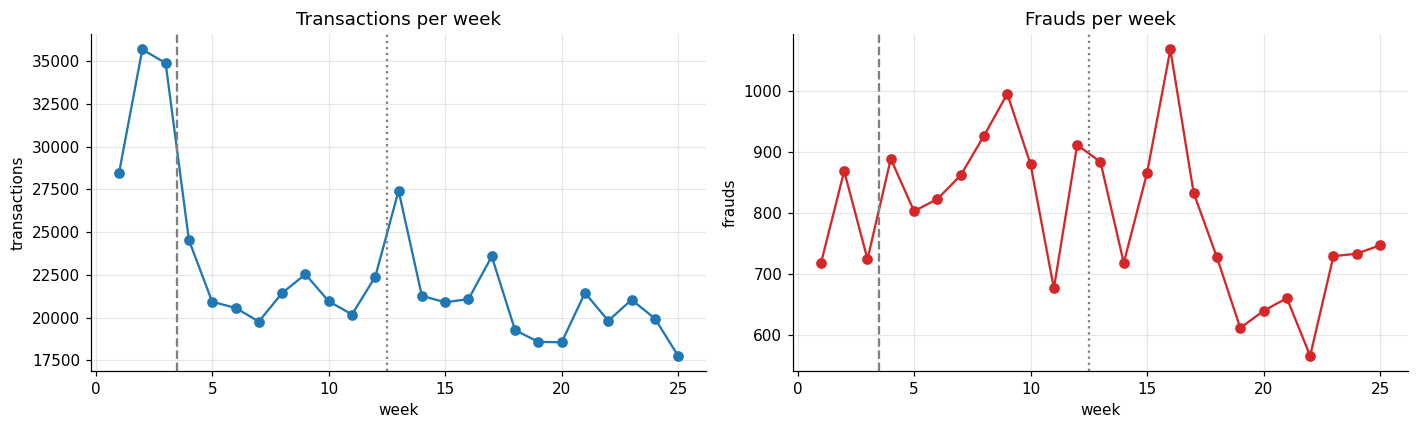

In [30]:
wk["legit"] = wk["n"] - wk["frauds"]
wk["step4"]  = (wk["week"] >= 4).astype(int)       # 1 from week 4 onward
wk["step13"] = (wk["week"] >= 13).astype(int)      # 1 from week 13 onward
gw["step4"]  = (gw["week"] >= 4).astype(int)
gw["step13"] = (gw["week"] >= 13).astype(int)

def fit_glm(formula, data, use_offset=True):
    off = data["log_n"] if use_offset else None
    return smf.glm(formula, data=data, family=sm.families.Poisson(), offset=off).fit(scale="X2")   # robust to overdispersion

def show(title, fit):
    print(title)
    ci = np.exp(fit.conf_int())
    for k in fit.params.index:
        if k == "Intercept":
            continue
        print(f"   {k:8s} multiplier {np.exp(fit.params[k]):.3f}  (95% CI {ci.loc[k, 0]:.3f} to {ci.loc[k, 1]:.3f}, p={fit.pvalues[k]:.3f})")

# 1) COUNTS (no exposure): did the number of frauds / legitimate transactions per week step at week 4?
show("Weekly number of FRAUDS ~ step at week 4 + week", fit_glm("frauds ~ step4 + week", wk, use_offset=False))
show("Weekly number of LEGITIMATE transactions ~ step at week 4 + week", fit_glm("legit ~ step4 + week", wk, use_offset=False))

# 2) RATE (with exposure): steps at weeks 4 and 13 plus a trend
show("\nFraud RATE, all transactions ~ step4 + step13 + week", fit_glm("frauds ~ step4 + step13 + week", wk))
for name, gg in gw.groupby("grp"):
    show(f"Fraud RATE, {name} ~ step4 + step13 + week", fit_glm("frauds ~ step4 + step13 + week", gg))

# 3) plot: observed weekly counts
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(wk["week"], wk["n"], "o-"); ax[0].set_title("Transactions per week"); ax[0].set_xlabel("week"); ax[0].set_ylabel("transactions")
ax[1].plot(wk["week"], wk["frauds"], "o-", color="C3"); ax[1].set_title("Frauds per week"); ax[1].set_xlabel("week"); ax[1].set_ylabel("frauds")
for a in ax:
    a.axvline(3.5, color="gray", ls="--"); a.axvline(12.5, color="gray", ls=":")
plt.tight_layout(); plt.show()

## Comparing regularised linear models and Weight of Evidence models

I prepare the training, validation, and future-test labels and create a preprocessing pipeline that imputes numeric values, adds missingness indicators, scales numeric features, and one-hot encodes low-cardinality categories. I use this common representation to compare Logistic Regression with L2, L1, and elastic-net penalties, recording validation PR-AUC, convergence, and the number of non-zero coefficients. I then construct a Weight of Evidence (WoE) representation: numeric features are divided into quantile bins, categorical values are grouped with rare or unseen categories, and missing values receive their own bin. Each bin is assigned a smoothed log ratio of fraud to legitimate transactions, and each feature receives an information-value summary. I fit regularised Logistic Regression models to the WoE features and select the best setting within each model family using validation PR-AUC. Only after selecting those settings do I report their performance on the future-test period.


In [53]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score

# ================= 0. labels and period masks for this step =================
if "scores" not in globals() and B:                                     # reference scores of the earlier models, from the saved bundle
    scores = B["scores"]
ytr, yva, yte = y[train_mask], y[val_mask], y[test_mask]
wk_te = week[test_mask]
early_m, late_m = np.isin(wk_te, [15, 16, 17]), np.isin(wk_te, [23, 24, 25])

# ================= 1. scaled matrix + "was missing" flags (fitted on TRAINING rows only) =================
numeric  = [c for c in X.columns if c not in text_cols]
low_card = [c for c in text_cols if df[c].nunique() <= 30]
prep = ColumnTransformer([
    ("num", Pipeline([("fill", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", QuantileTransformer(n_quantiles=200, subsample=100_000,
                                                    output_distribution="normal", random_state=42))]), numeric),
    ("cat", Pipeline([("fill", SimpleImputer(strategy="constant", fill_value=-1)),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20))]), low_card),
], sparse_threshold=0)
t0 = time.time()
Xtr_t = prep.fit_transform(X[train_mask]).astype("float32")
Xva_t = prep.transform(X[val_mask]).astype("float32")
Xte_t = prep.transform(X[test_mask]).astype("float32")
print("scaled matrix:", Xtr_t.shape, "|", round(time.time() - t0), "s")

# ================= 2. helper: fit one logistic regression and remember how it did on VALIDATION =================
rows, fits = [], {}

def run(name, family, Xa_tr, Xa_va, Xa_te, **kw):
    t0 = time.time()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        m = LogisticRegression(class_weight="balanced", **kw).fit(Xa_tr, ytr)
    converged = not any(issubclass(c.category, ConvergenceWarning) for c in caught)
    val_pr = average_precision_score(yva, m.decision_function(Xa_va))
    rows.append({"model": name, "family": family, "val_PR_AUC": val_pr, "converged": converged,
                 "nonzero_coefs": int((m.coef_ != 0).sum()), "seconds": round(time.time() - t0)})
    fits[name] = (m, Xa_te)
    print(f"{name:42s} val PR-AUC {val_pr:.3f} | converged: {converged} | {round(time.time() - t0)} s")

# ================= 3. penalties: L2, L1, elastic net (smaller C = stronger penalty) =================
for reg in [0.001, 0.01, 0.1]:
    run(f"L2, C={reg}", "L2 (ridge)", Xtr_t, Xva_t, Xte_t, solver="lbfgs", max_iter=300, C=reg)
for reg in [0.003, 0.01, 0.1]:                                       # liblinear: converges reliably and gives exact zeros
    run(f"L1, C={reg}", "L1 (lasso)", Xtr_t, Xva_t, Xte_t, penalty="l1", solver="liblinear", max_iter=200, tol=1e-3, C=reg)
for reg in [0.01, 0.1]:
    run(f"Elastic net (50/50), C={reg}", "Elastic net", Xtr_t, Xva_t, Xte_t, penalty="elasticnet", l1_ratio=0.5,
        solver="saga", max_iter=100, tol=1e-3, C=reg)

# ================= 4. weight-of-evidence (WoE) binning, the credit-scorecard approach =================
# Each feature is cut into up to 10 quantile bins (plus a "missing" bin). Every bin gets ln(share of frauds / share of normals);
# positive = riskier than average. Text-coded columns use their categories (rare ones pooled). Fitted on TRAINING rows only.
def woe_key(x, spec):
    if spec["is_cat"]:
        key = np.where(np.isin(x, spec["known"]), x, -2.0)           # -2 = rare / unseen category
    else:
        key = np.searchsorted(spec["edges"], x, side="right").astype("float64")
    return np.where(np.isnan(x), -1.0, key)                          # -1 = missing

def woe_fit(x, yy, is_cat, n_bins=10, min_count=100):
    spec = {"is_cat": is_cat}
    nn = x[~np.isnan(x)]
    if is_cat:
        vals, cnt = np.unique(nn, return_counts=True)
        spec["known"] = vals[cnt >= min_count]
    else:
        spec["edges"] = np.unique(np.quantile(nn, np.linspace(0, 1, n_bins + 1))[1:-1]) if len(nn) else np.array([])
    tab = pd.DataFrame({"k": woe_key(x, spec), "bad": yy}).groupby("k")["bad"].agg(bad="sum", n="count")
    good, k = tab["n"] - tab["bad"], len(tab)
    pb = (tab["bad"] + 0.5) / (tab["bad"].sum() + 0.5 * k)           # smoothed share of frauds in each bin
    pg = (good + 0.5) / (good.sum() + 0.5 * k)                       # smoothed share of normal transactions
    woe = np.log(pb / pg)
    spec["woe"], spec["iv"] = woe.to_dict(), float(((pb - pg) * woe).sum())   # iv = information value (strength of the feature)
    return spec

def woe_apply(x, spec):
    return pd.Series(woe_key(x, spec)).map(spec["woe"]).fillna(0.0).values.astype("float32")

t0 = time.time()
cols, cat_set = list(X.columns), set(text_cols)
Xtr_df, Xva_df, Xte_df = X[train_mask], X[val_mask], X[test_mask]
specs = {c: woe_fit(Xtr_df[c].values, ytr, c in cat_set) for c in cols}
Wtr = np.column_stack([woe_apply(Xtr_df[c].values, specs[c]) for c in cols])
Wva = np.column_stack([woe_apply(Xva_df[c].values, specs[c]) for c in cols])
Wte = np.column_stack([woe_apply(Xte_df[c].values, specs[c]) for c in cols])
print("WoE matrix:", Wtr.shape, "|", round(time.time() - t0), "s")

iv = pd.Series({c: specs[c]["iv"] for c in cols}).sort_values(ascending=False)
print("\nStrongest single features by information value (>0.3 strong, 0.1-0.3 medium, <0.02 useless):")
print(pd.DataFrame({"IV": iv.head(10).round(3), "family": [family(c) for c in iv.head(10).index]}).to_string())
print("features with IV > 0.1:", int((iv > 0.1).sum()), "of", len(iv), "\n")

for reg in [0.01, 0.1, 1]:
    run(f"WoE + L2, C={reg}", "WoE + L2", Wtr, Wva, Wte, solver="lbfgs", max_iter=300, C=reg)

# ================= 5. choose by VALIDATION, then look at the future test once =================
res = pd.DataFrame(rows)
print("\nAll settings tried, judged on the VALIDATION weeks only:")
print(res.sort_values("val_PR_AUC", ascending=False).round(3).to_string(index=False))

best = res.loc[res.groupby("family")["val_PR_AUC"].idxmax()]
final = []
for _, r in best.iterrows():
    m, Xa_te = fits[r.model]
    s = m.decision_function(Xa_te)
    final.append({"model": r.model, "val_PR_AUC": r.val_PR_AUC, "ROC-AUC": roc_auc_score(yte, s),
                  "PR-AUC all": average_precision_score(yte, s),
                  "PR-AUC early": average_precision_score(yte[early_m], s[early_m]),
                  "PR-AUC late": average_precision_score(yte[late_m], s[late_m]), "nonzero": r.nonzero_coefs, "converged": r.converged})
if "scores" in globals() and "lightgbm" in scores:                      # reference rows from earlier in the notebook
    for n in ["lightgbm", "logreg"]:
        s = scores[n]
        final.append({"model": f"(reference) {n}", "val_PR_AUC": np.nan, "ROC-AUC": roc_auc_score(yte, s),
                      "PR-AUC all": average_precision_score(yte, s), "PR-AUC early": average_precision_score(yte[early_m], s[early_m]),
                      "PR-AUC late": average_precision_score(yte[late_m], s[late_m]), "nonzero": np.nan, "converged": np.nan})
final = pd.DataFrame(final).set_index("model")
final["relative drop %"] = ((final["PR-AUC early"] - final["PR-AUC late"]) / final["PR-AUC early"] * 100).round(0)
print("\nBest setting of each kind (chosen on validation), scored on the future test weeks:")
print(final.round(3).to_string())

scaled matrix: (292338, 376) | 30 s
L2, C=0.001                                val PR-AUC 0.312 | converged: False | 54 s
L2, C=0.01                                 val PR-AUC 0.304 | converged: False | 53 s
L2, C=0.1                                  val PR-AUC 0.303 | converged: False | 54 s
L1, C=0.003                                val PR-AUC 0.324 | converged: True | 351 s
L1, C=0.01                                 val PR-AUC 0.318 | converged: True | 746 s
L1, C=0.1                                  val PR-AUC 0.314 | converged: True | 2852 s
Elastic net (50/50), C=0.01                val PR-AUC 0.302 | converged: False | 293 s
Elastic net (50/50), C=0.1                 val PR-AUC 0.300 | converged: False | 312 s
WoE matrix: (292338, 207) | 11 s

Strongest single features by information value (>0.3 strong, 0.1-0.3 medium, <0.02 useless):
                  IV    family
V90            0.553         V
V69            0.544         V
V29            0.537         V
id_31          0.536  

## Comparing boosted trees with a logistic model on tree leaves

I fit several boosted-tree configurations with different numbers of trees and depths, using validation PR-AUC to assess the tree model. For each configuration, I encode the terminal leaf reached by every transaction as a one-hot feature and fit Logistic Regression to those leaf indicators at several regularisation strengths. This creates a hybrid model in which the trees define groups of transactions and the logistic model combines the resulting leaf indicators. I store the fitted models and their future-test leaf matrices, select the best hybrid configuration using validation PR-AUC, and then compare it on the future-test data with the same tree model used on its own.


In [41]:
import warnings
from scipy import sparse
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score

X_tr, X_va, X_te = X[train_mask], X[val_mask], X[test_mask]
ytr, yva, yte = y[train_mask], y[val_mask], y[test_mask]
wk_te = week[test_mask]
early_m, late_m = np.isin(wk_te, [15, 16, 17]), np.isin(wk_te, [23, 24, 25])

rows, fits = [], {}
for n_trees, depth in [(100, 3), (300, 3), (100, 5), (300, 5)]:
    t0 = time.time()
    gbm = lgb.LGBMClassifier(n_estimators=n_trees, learning_rate=0.1, max_depth=depth, num_leaves=2 ** depth,
                             colsample_bytree=0.5, subsample=0.8, subsample_freq=1, scale_pos_weight=5,
                             metric="average_precision", random_state=42, verbose=-1).fit(X_tr, ytr)
    trees_val = average_precision_score(yva, gbm.predict_proba(X_va)[:, 1])
    enc = OneHotEncoder(handle_unknown="ignore")                       # one yes/no column per leaf
    L_tr = enc.fit_transform(gbm.predict(X_tr, pred_leaf=True))
    L_va = enc.transform(gbm.predict(X_va, pred_leaf=True))
    L_te = enc.transform(gbm.predict(X_te, pred_leaf=True))
    print(f"{n_trees} trees, depth {depth}: {L_tr.shape[1]} leaf columns | trees fitted in {round(time.time() - t0)} s")
    for reg in [0.003, 0.01, 0.03]:
        t1 = time.time()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            lr = LogisticRegression(C=reg, max_iter=200, class_weight="balanced").fit(L_tr, ytr)
        ok = not any(issubclass(c.category, ConvergenceWarning) for c in caught)
        hyb_val = average_precision_score(yva, lr.decision_function(L_va))
        rows.append({"trees": n_trees, "depth": depth, "C": reg, "leaf_columns": L_tr.shape[1],
                     "trees_alone_val": trees_val, "hybrid_val": hyb_val, "converged": ok})
        fits[(n_trees, depth, reg)] = (lr, L_te, gbm)
        print(f"     C={reg}: hybrid val PR-AUC {hyb_val:.3f} (trees alone {trees_val:.3f}) | converged: {ok} | {round(time.time() - t1)} s")

res = pd.DataFrame(rows)
print("\nAll settings, judged on the VALIDATION weeks:")
print(res.sort_values("hybrid_val", ascending=False).round(3).to_string(index=False))

# ---- choose on validation, then look at the future test once ----
b = res.loc[res["hybrid_val"].idxmax()]
key = (int(b.trees), int(b.depth), float(b.C))
lr, L_te, gbm = fits[key]
def summarize(name, s):
    return {"model": name, "ROC-AUC": roc_auc_score(yte, s), "PR-AUC all": average_precision_score(yte, s),
            "PR-AUC early": average_precision_score(yte[early_m], s[early_m]), "PR-AUC late": average_precision_score(yte[late_m], s[late_m])}
final = [summarize(f"hybrid (chosen: {key[0]} trees, depth {key[1]}, C={key[2]})", lr.decision_function(L_te)),
         summarize(f"trees alone (same {key[0]} trees, depth {key[1]})", gbm.predict_proba(X_te)[:, 1])]
if "scores" in globals() and "lightgbm" in scores:
    final += [summarize("(reference) lightgbm, full boosting", scores["lightgbm"]), summarize("(reference) old logreg", scores["logreg"])]
final = pd.DataFrame(final).set_index("model")
final["relative drop %"] = ((final["PR-AUC early"] - final["PR-AUC late"]) / final["PR-AUC early"] * 100).round(0)
print("\nChosen on validation, scored on the future test weeks:")
print(final.round(3).to_string())

100 trees, depth 3: 787 leaf columns | trees fitted in 22 s
     C=0.003: hybrid val PR-AUC 0.464 (trees alone 0.426) | converged: True | 21 s
     C=0.01: hybrid val PR-AUC 0.461 (trees alone 0.426) | converged: True | 13 s
     C=0.03: hybrid val PR-AUC 0.458 (trees alone 0.426) | converged: True | 22 s
300 trees, depth 3: 2336 leaf columns | trees fitted in 51 s
     C=0.003: hybrid val PR-AUC 0.485 (trees alone 0.471) | converged: True | 38 s
     C=0.01: hybrid val PR-AUC 0.480 (trees alone 0.471) | converged: True | 56 s
     C=0.03: hybrid val PR-AUC 0.472 (trees alone 0.471) | converged: False | 65 s
100 trees, depth 5: 2817 leaf columns | trees fitted in 22 s
     C=0.003: hybrid val PR-AUC 0.484 (trees alone 0.473) | converged: True | 17 s
     C=0.01: hybrid val PR-AUC 0.482 (trees alone 0.473) | converged: True | 25 s
     C=0.03: hybrid val PR-AUC 0.476 (trees alone 0.473) | converged: True | 21 s
300 trees, depth 5: 8104 leaf columns | trees fitted in 57 s
     C=0.003: h

## Rebuilding the feature matrix for the coefficient analysis

I repeat the feature-screening and encoding procedure used earlier: I remove the target and time or identifier columns, exclude features that are almost entirely missing or constant, and remove near-duplicate `V` variables based on their training-period correlations. I then factorize the remaining text columns and convert the feature matrix to `float32`. This produces a consistent numeric design matrix for the analysis that follows, and I verify that its feature columns agree with the saved-model specification when the saved bundle is being used.


In [40]:
not_features = ["isFraud", "TransactionID", "TransactionDT", "week", "day"]
candidates = [c for c in df.columns if c not in not_features]
train = df.loc[train_mask, candidates]

# rule 1: nearly empty or constant
too_empty = train.isna().mean()[lambda s: s > 0.95].index.tolist()
constant  = train.nunique()[lambda s: s <= 1].index.tolist()
print("More than 95% missing:", len(too_empty), too_empty)
print("Constant:", len(constant), constant)

# rule 2: near-duplicate V columns
v_cols = [c for c in candidates if c.startswith("V") and c[1:].isdigit() and c not in too_empty and c not in constant]
sample = df.loc[train_mask, v_cols].sample(min(100_000, int(train_mask.sum())), random_state=42)
corr = sample.corr().abs()
kept = []
for c in v_cols:
    if all(corr.loc[c, k] <= 0.95 for k in kept):
        kept.append(c)
dropped_v = [c for c in v_cols if c not in kept]
print(f"V columns: {len(v_cols)} -> kept {len(kept)}, dropped {len(dropped_v)} as near-duplicates")

feature_cols = [c for c in candidates if c not in too_empty and c not in constant and c not in dropped_v]
text_cols = [c for c in feature_cols if not pd.api.types.is_numeric_dtype(df[c])]
print("Feature columns:", len(feature_cols), "| text columns:", len(text_cols))

# rule 3: text -> numbers (order of first appearance; missing stays missing)
X = df[feature_cols].copy()
for c in text_cols:
    codes, _ = pd.factorize(X[c])
    codes = codes.astype("float32")
    codes[codes < 0] = np.nan
    X[c] = codes
X = X.astype("float32")
print("X shape:", X.shape, "| all columns numeric:", bool((X.dtypes == "float32").all()))

if not TRAIN_FROM_SCRATCH:                                     # the saved models expect exactly these columns
    print("Same columns as the saved models:", feature_cols == B["feature_cols"])

More than 95% missing: 9 ['id_07', 'id_08', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27']
Constant: 2 ['V1', 'V107']
V columns: 337 -> kept 124, dropped 213 as near-duplicates
Feature columns: 207 | text columns: 29
X shape: (590540, 207) | all columns numeric: True
Same columns as the saved models: True


## Measuring coefficient drift over consecutive time windows

I examine whether the relationship between selected features and fraud changes over time in a logistic-regression representation. I first select the 40 features with the highest gain importance in the static LightGBM model, then build a fixed design matrix using medians, interquartile-range scaling, and missingness indicators estimated from the training period. I fit Logistic Regression separately on six consecutive four-week windows. Within each window, I split the data into two random halves to estimate how much the coefficients vary due to sampling noise. I compare coefficient changes across windows with this noise estimate, identify large changes and sign reversals, and calculate the rank correlations between coefficient vectors. The final plot displays how the largest coefficients move across the windows, with sampling-noise bars for context.


32 numeric + 3 categorical features
design matrix: (590540, 59)

Coefficients of the 12 largest effects (log-odds per IQR, or for a yes/no column):
                 wk 1-4  wk 5-8  wk 9-12  wk 13-16  wk 17-20  wk 21-24  noise (+/-)
C7                 0.12    1.93     2.29      1.86      1.78      0.73         0.09
V62 [missing]      1.46    1.63     1.53      1.12      0.99      1.17         0.12
C1                 1.13    1.12     1.17      1.01      0.66      0.97         0.03
M4 [missing]      -1.49   -0.96    -0.73     -0.73     -1.07     -0.79         0.07
C14               -0.76   -0.92    -0.90     -0.85     -0.70     -0.89         0.02
card2 [missing]    0.38    0.68     1.46      0.03     -0.41     -0.80         0.16
card6 = code 1    -0.90   -0.70    -0.19     -0.60     -0.83     -0.20         0.06
D8                -0.50   -0.48    -0.44     -0.44     -0.71     -0.69         0.06
id_02 [missing]   -0.38   -0.11    -1.16     -0.76     -0.28     -0.38         0.09
id_12 = code

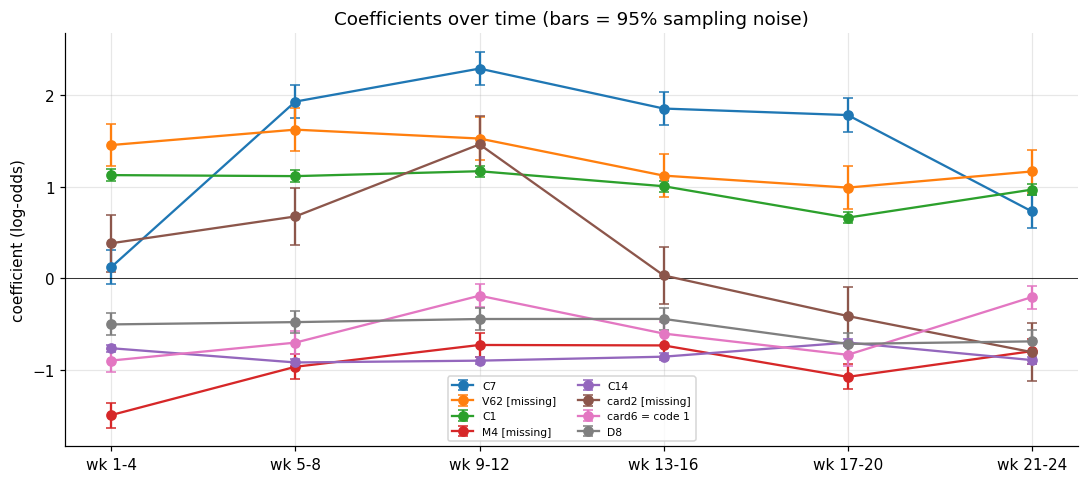

In [39]:
# ================= Coefficient drift: does a regression's view of "what predicts fraud" change over time? =================
# Logistic regression with a FIXED design (same scaling for all windows), refitted on consecutive 4-week windows.
# Sampling noise is measured by splitting each window into two random halves: a coefficient change only counts
# if it is clearly larger than that noise.
rng = np.random.RandomState(0)

# ---- 1. the 40 features the static model relies on most ----
if B and "model_cache" in B:
    gain = pd.Series(B["model_cache"][(15, None)].booster_.feature_importance(importance_type="gain"), index=X.columns)
else:                                                                     # session without the saved bundle: quick small model
    quick = lgb.LGBMClassifier(n_estimators=100, learning_rate=0.1, num_leaves=64, colsample_bytree=0.5, subsample=0.8,
                               subsample_freq=1, scale_pos_weight=5, random_state=42, verbose=-1).fit(X[train_mask], y[train_mask])
    gain = pd.Series(quick.booster_.feature_importance(importance_type="gain"), index=X.columns)
top = list(gain.sort_values(ascending=False).index[:40])
num_top = [c for c in top if c not in text_cols]
cat_top = [c for c in top if c in text_cols and df[c].nunique() <= 30]       # small text columns become yes/no dummies
print(f"{len(num_top)} numeric + {len(cat_top)} categorical features")

# ---- 2. fixed design, fitted on the training weeks only ----
tr_rows = X[train_mask]
spec = {}
for c in num_top:
    col = tr_rows[c]
    q1, q3 = col.quantile([0.25, 0.75])
    scale = (q3 - q1) or col.std() or 1.0                                  # one unit = one inter-quartile range
    spec[c] = (col.median(), scale, col.isna().mean() > 0.005)
levels = {c: [k for k, s in tr_rows[c].value_counts(normalize=True).items() if s >= 0.02] for c in cat_top}
has_missing = {c: tr_rows[c].isna().mean() > 0.005 for c in cat_top}

def design(rows):
    parts = {}
    for c in num_top:
        med, scale, flag = spec[c]
        v = rows[c]
        parts[c] = ((v.fillna(med) - med) / scale).clip(-5, 5)
        if flag:
            parts[c + " [missing]"] = v.isna().astype(float)
    for c in cat_top:
        for code in levels[c]:
            parts[f"{c} = code {int(code)}"] = (rows[c] == code).astype(float)
        if has_missing[c]:
            parts[c + " [missing]"] = rows[c].isna().astype(float)
    return pd.DataFrame(parts).astype("float32")

D = design(X)
names = list(D.columns)
print("design matrix:", D.shape)

# ---- 3. one logistic regression per 4-week window (+ two random halves for the noise estimate) ----
windows = {"wk 1-4": (1, 4), "wk 5-8": (5, 8), "wk 9-12": (9, 12), "wk 13-16": (13, 16), "wk 17-20": (17, 20), "wk 21-24": (21, 24)}
def fit(idx):
    return LogisticRegression(C=0.1, max_iter=500).fit(D.iloc[idx], y[idx]).coef_[0]

beta, noise_sq = pd.DataFrame(index=names), np.zeros(len(names))
for w, (a, b) in windows.items():
    idx = np.where((week >= a) & (week <= b))[0]
    beta[w] = fit(idx)
    perm = rng.permutation(idx)
    half = len(perm) // 2
    noise_sq += (fit(perm[:half]) - fit(perm[half:])) ** 2
sigma = pd.Series(np.sqrt(noise_sq / len(windows)) / 2, index=names)       # sampling noise (std) of one full-window coefficient
se_diff = sigma * np.sqrt(2)                                              # noise of a difference between two windows
z_first = beta.sub(beta.iloc[:, 0], axis=0).div(se_diff, axis=0)           # change vs the first window
z_prev = beta.diff(axis=1).div(se_diff, axis=0)                           # change vs the previous window

# ---- 4. results ----
big = beta.abs().mean(axis=1).sort_values(ascending=False).index[:12]
tab = beta.loc[big].round(2); tab["noise (+/-)"] = sigma.loc[big].round(2)
print("\nCoefficients of the 12 largest effects (log-odds per IQR, or for a yes/no column):")
print(tab.to_string())

print("\nShare of coefficients that changed MORE than 3x the sampling noise:")
res = pd.DataFrame({"vs first window (wk 1-4)": (z_first.abs() > 3).mean(), "vs previous window": (z_prev.abs() > 3).mean()}).drop(index="wk 1-4", errors="ignore")
print((res * 100).round(0).astype(int).astype(str).add("%").to_string())

is_miss = pd.Series([n.endswith("[missing]") for n in names], index=names)
print("\nOf the coefficients that changed (vs first window, last window wk 21-24):")
print(f"   'missing' flags : {int((z_first['wk 21-24'].abs() > 3)[is_miss].sum())} of {int(is_miss.sum())}")
print(f"   value features  : {int((z_first['wk 21-24'].abs() > 3)[~is_miss].sum())} of {int((~is_miss).sum())}")

move = z_first["wk 21-24"].abs().sort_values(ascending=False).index[:10]
print("\nLargest changes, first vs last window:")
print(pd.DataFrame({"wk 1-4": beta.loc[move, "wk 1-4"], "wk 21-24": beta.loc[move, "wk 21-24"],
                    "z (change / noise)": z_first.loc[move, "wk 21-24"]}).round(2).to_string())

strong = [n for n in names if abs(beta.loc[n, "wk 1-4"]) > 2 * sigma[n] and abs(beta.loc[n, "wk 21-24"]) > 2 * sigma[n]]
flips = [n for n in strong if np.sign(beta.loc[n, "wk 1-4"]) != np.sign(beta.loc[n, "wk 21-24"])]
print("\nSign flips among clearly non-zero coefficients:", flips if flips else "none")
print("\nSpearman correlation between the coefficient vectors of different windows:")
print(beta.corr(method="spearman").round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
for n in big[:8]:
    ax.errorbar(range(len(windows)), beta.loc[n], yerr=1.96 * sigma[n], marker="o", capsize=3, label=n)
ax.set_xticks(range(len(windows))); ax.set_xticklabels(list(windows)); ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("coefficient (log-odds)"); ax.set_title("Coefficients over time (bars = 95% sampling noise)"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## Supplementary figures from the reported result tables

I create an additional set of report figures using summary values already recorded in the notebook, rather than rerunning the underlying model experiments. The figures bring the main comparisons together: the model-performance ladder; the effect of tree depth and the hybrid approach; cost savings and retraining break-even values; the trade-off between retraining frequency and performance under label delay; SHAP-importance stability; coefficient drift; changes in feature availability; and the weekly level-shift analysis. I save these figures in a separate `extra` folder so they can be included alongside the main report figures.


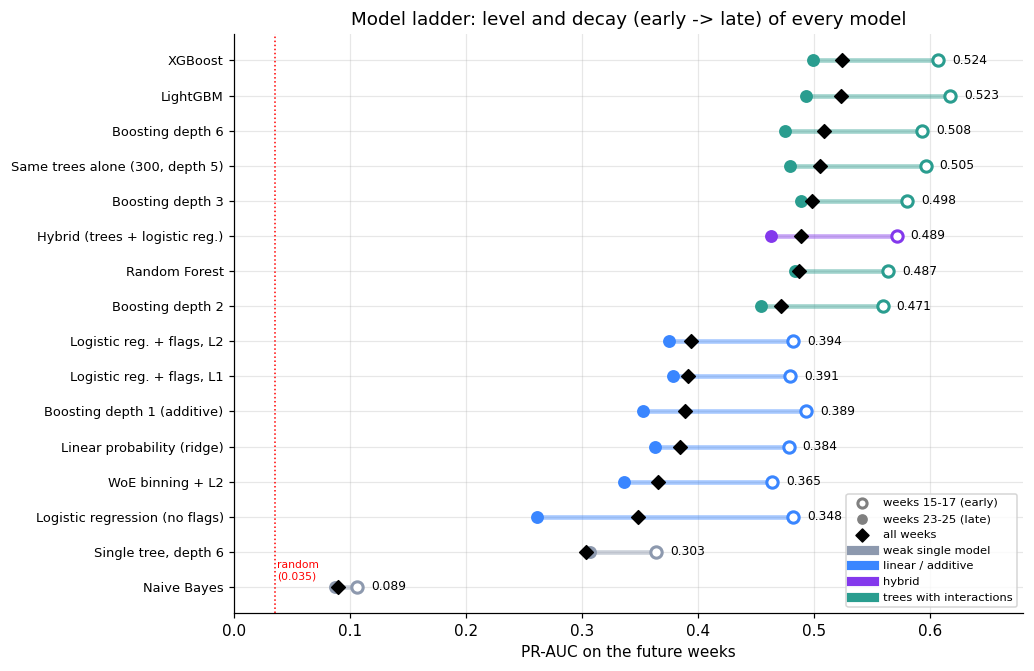

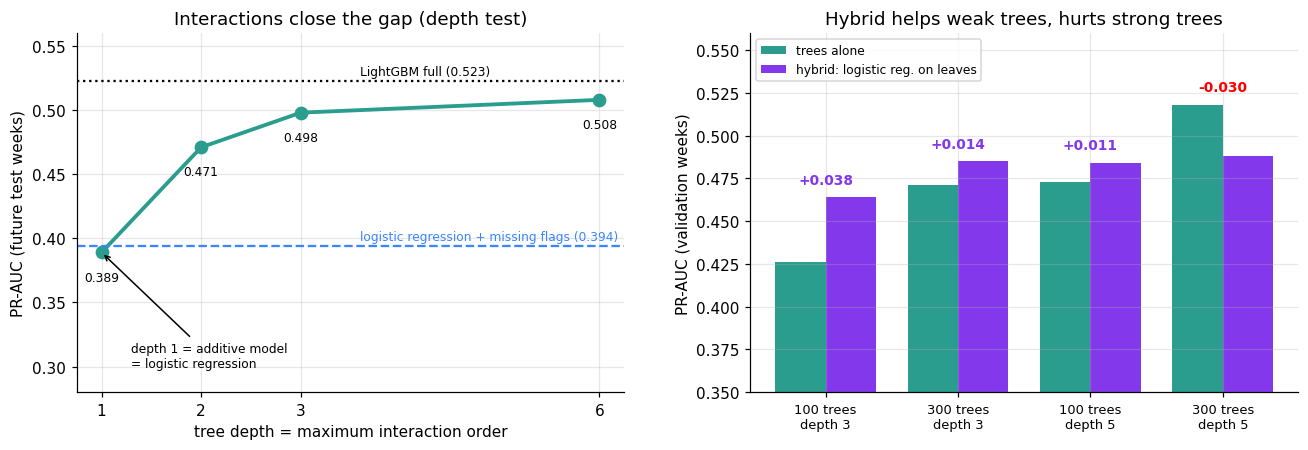

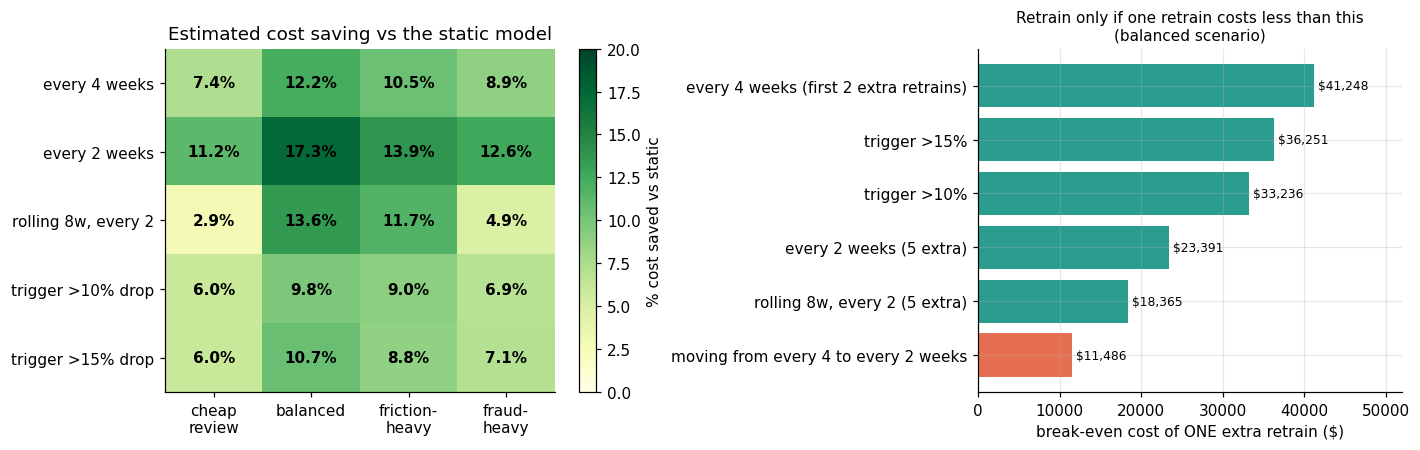

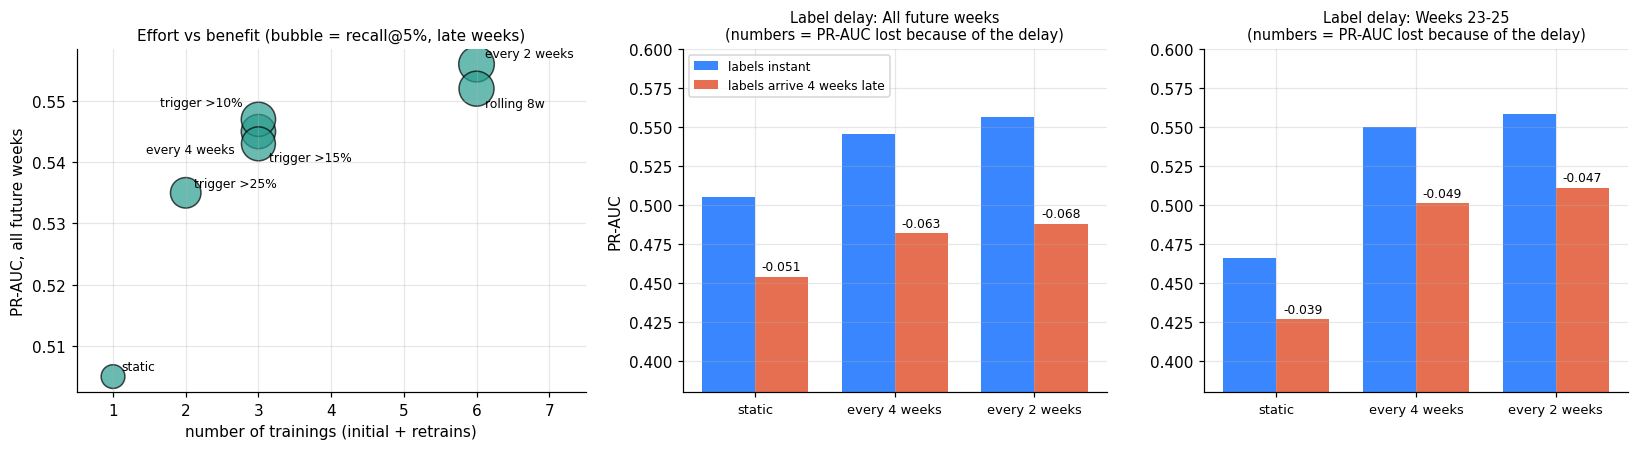

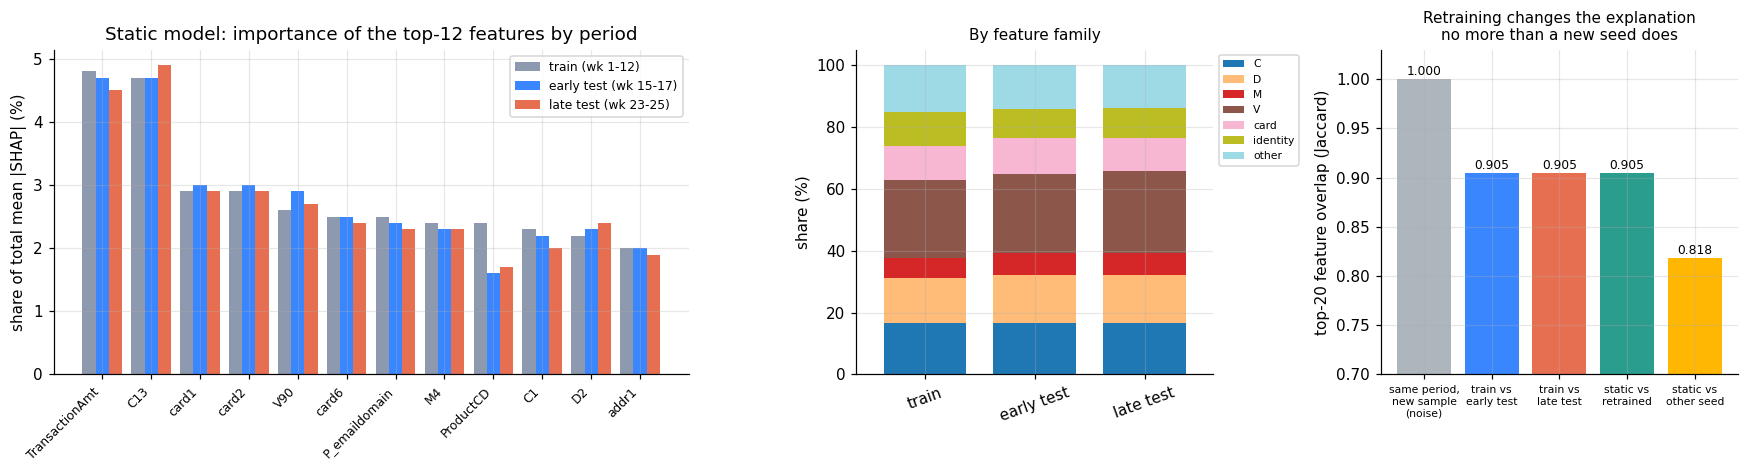

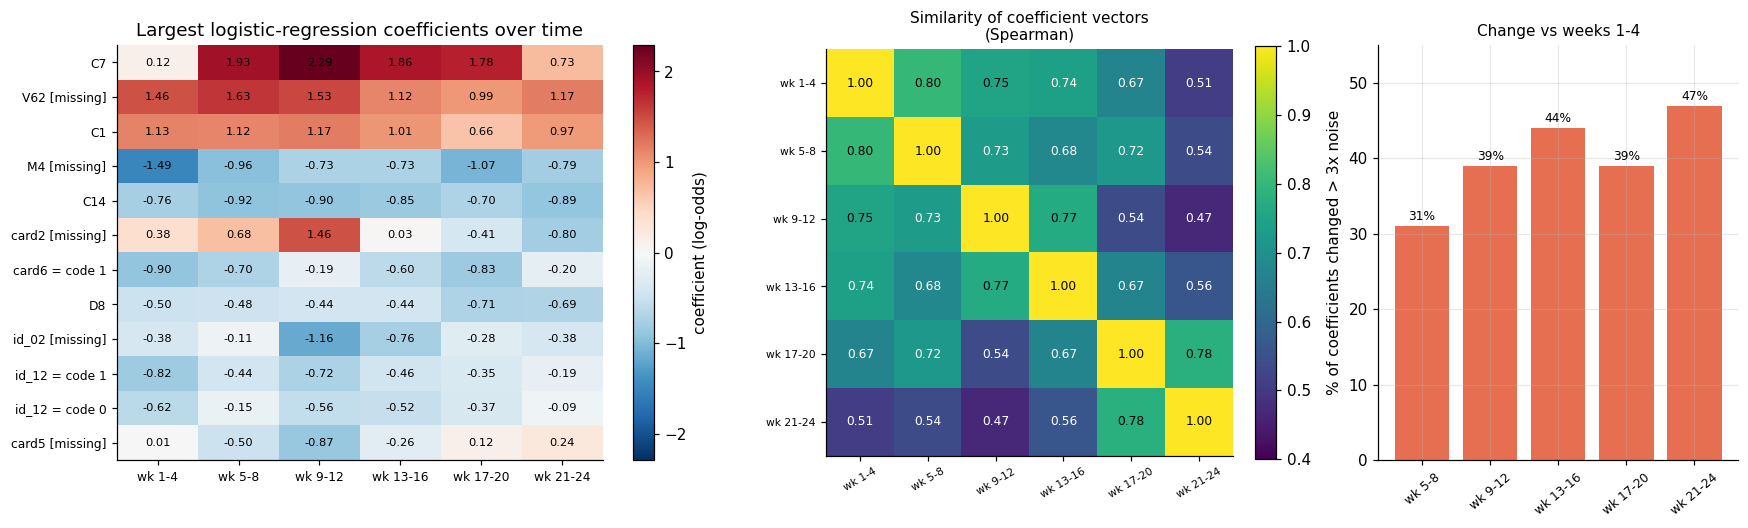

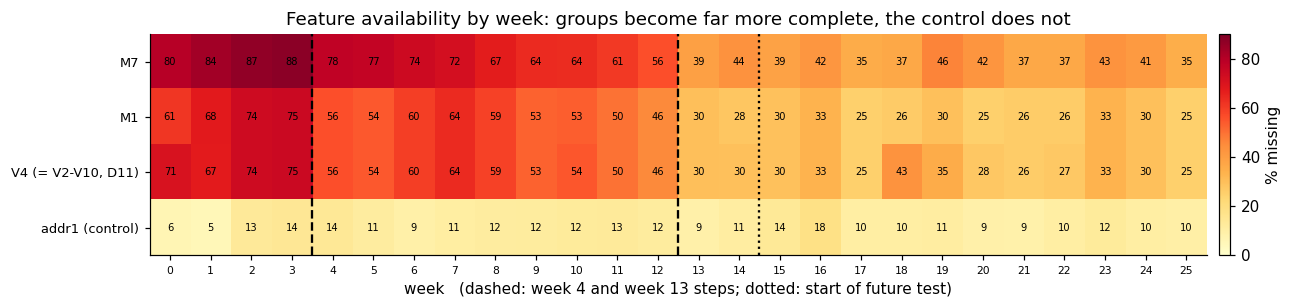

check against earlier output -> rate step4 1.750 (1.750), step13 0.924 (0.924), trend 0.997 (0.997); frauds step4 1.226 (1.226), legit step4 0.675 (0.675)


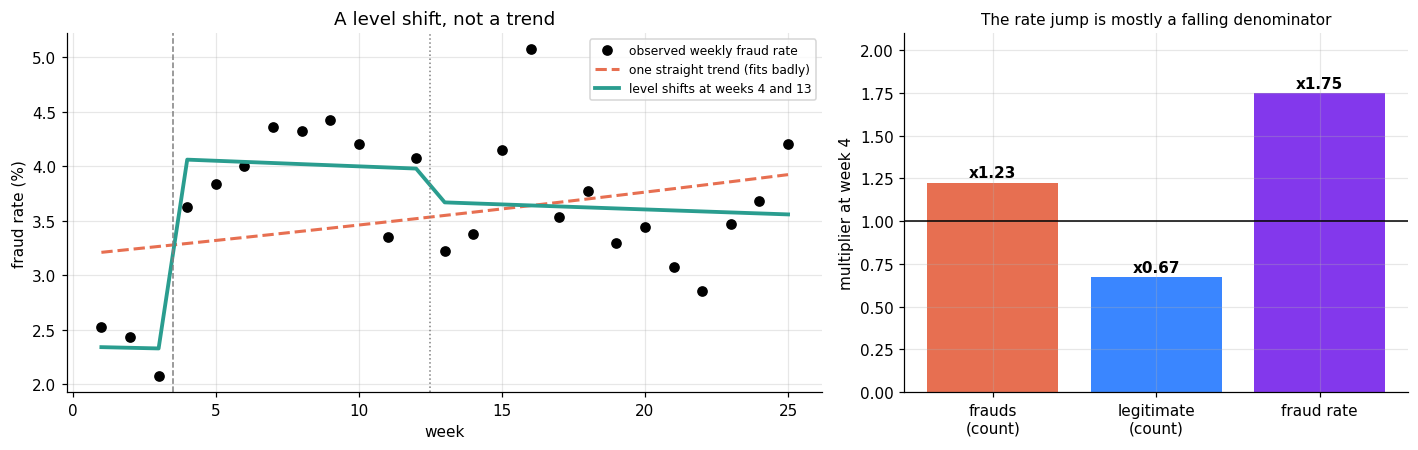

saved: ['extraA_model_ladder.png', 'extraB_interactions_and_hybrid.png', 'extraC_cost_heatmap_breakeven.png', 'extraD_efficiency_and_label_delay.png', 'extraE_shap_stability.png', 'extraF_coefficient_drift_overview.png', 'extraG_missing_heatmap.png', 'extraH_week4_level_shift.png']


In [37]:
# ======================= EXTRA FIGURES, SET 1: drawn from the exact result tables (no data needed, runs in ~30 s) =======================
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

OUT = "/kaggle/working/report/extra"
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.tight_layout(); fig.savefig(f"{OUT}/{name}.png", dpi=200, bbox_inches="tight"); plt.show()

# ------------------------------------------------------------------ A. the model ladder
# (name, PR-AUC all weeks, weeks 15-17, weeks 23-25, family)
M = [("Naive Bayes", .089, .106, .087, "weak single model"), ("Single tree, depth 6", .303, .364, .307, "weak single model"),
     ("WoE binning + L2", .365, .464, .336, "linear / additive"), ("Logistic regression (no flags)", .348, .482, .261, "linear / additive"),
     ("Linear probability (ridge)", .384, .478, .363, "linear / additive"), ("Boosting depth 1 (additive)", .389, .493, .352, "linear / additive"),
     ("Logistic reg. + flags, L1", .391, .479, .378, "linear / additive"), ("Logistic reg. + flags, L2", .394, .482, .375, "linear / additive"),
     ("Boosting depth 2", .471, .559, .454, "trees with interactions"), ("Random Forest", .487, .564, .483, "trees with interactions"),
     ("Hybrid (trees + logistic reg.)", .489, .571, .463, "hybrid"), ("Boosting depth 3", .498, .580, .489, "trees with interactions"),
     ("Same trees alone (300, depth 5)", .505, .596, .479, "trees with interactions"), ("Boosting depth 6", .508, .593, .475, "trees with interactions"),
     ("LightGBM", .523, .617, .493, "trees with interactions"), ("XGBoost", .524, .607, .499, "trees with interactions")]
col = {"weak single model": "#8d99ae", "linear / additive": "#3a86ff", "hybrid": "#8338ec", "trees with interactions": "#2a9d8f"}
M = sorted(M, key=lambda r: r[1])
fig, ax = plt.subplots(figsize=(9.5, 6.2))
for i, (n, a, e, l, f) in enumerate(M):
    ax.plot([l, e], [i, i], color=col[f], lw=3, alpha=.45)
    ax.scatter(e, i, s=55, facecolor="white", edgecolor=col[f], lw=2, zorder=3)
    ax.scatter(l, i, s=55, color=col[f], zorder=3)
    ax.scatter(a, i, marker="D", s=40, color="black", zorder=4)
    ax.text(max(e, a) + .012, i, f"{a:.3f}", va="center", fontsize=8)
ax.set_yticks(range(len(M))); ax.set_yticklabels([m[0] for m in M], fontsize=8.5)
ax.set_xlabel("PR-AUC on the future weeks"); ax.set_xlim(0, .68)
ax.scatter([], [], facecolor="white", edgecolor="gray", lw=2, label="weeks 15-17 (early)"); ax.scatter([], [], color="gray", label="weeks 23-25 (late)")
ax.scatter([], [], marker="D", color="black", label="all weeks")
for f, c in col.items(): ax.plot([], [], color=c, lw=6, label=f)
ax.axvline(.035, color="red", ls=":", lw=1); ax.text(.037, .2, "random\n(0.035)", color="red", fontsize=7)
ax.legend(fontsize=7.5, loc="lower right"); ax.set_title("Model ladder: level and decay (early -> late) of every model")
save(fig, "extraA_model_ladder")

# ------------------------------------------------------------------ B. why trees win: depth curve + hybrid vs its own trees
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
d, p = [1, 2, 3, 6], [.389, .471, .498, .508]
ax[0].plot(d, p, "o-", color="#2a9d8f", lw=2.5, ms=8, label="boosted trees of depth d")
ax[0].axhline(.394, color="#3a86ff", ls="--"); ax[0].text(3.6, .399, "logistic regression + missing flags (0.394)", color="#3a86ff", fontsize=8)
ax[0].axhline(.523, color="k", ls=":"); ax[0].text(3.6, .527, "LightGBM full (0.523)", fontsize=8)
for x, y_ in zip(d, p): ax[0].text(x, y_ - .022, f"{y_:.3f}", ha="center", fontsize=8)
ax[0].annotate("depth 1 = additive model\n= logistic regression", (1, .389), (1.3, .30), arrowprops=dict(arrowstyle="->"), fontsize=8)
ax[0].set_xticks(d); ax[0].set_xlabel("tree depth = maximum interaction order"); ax[0].set_ylabel("PR-AUC (future test weeks)"); ax[0].set_ylim(.28, .56)
ax[0].set_title("Interactions close the gap (depth test)")
lab = ["100 trees\ndepth 3", "300 trees\ndepth 3", "100 trees\ndepth 5", "300 trees\ndepth 5"]
tv, hv = np.array([.426, .471, .473, .518]), np.array([.464, .485, .484, .488]); x = np.arange(4)
ax[1].bar(x - .19, tv, .38, label="trees alone", color="#2a9d8f"); ax[1].bar(x + .19, hv, .38, label="hybrid: logistic reg. on leaves", color="#8338ec")
for i in x: ax[1].text(i, max(tv[i], hv[i]) + .008, f"{hv[i]-tv[i]:+.3f}", ha="center", fontsize=9, fontweight="bold", color="#8338ec" if hv[i] > tv[i] else "red")
ax[1].set_xticks(x); ax[1].set_xticklabels(lab, fontsize=8.5); ax[1].set_ylim(.35, .56); ax[1].set_ylabel("PR-AUC (validation weeks)")
ax[1].legend(fontsize=8, loc="upper left"); ax[1].set_title("Hybrid helps weak trees, hurts strong trees")
save(fig, "extraB_interactions_and_hybrid")

# ------------------------------------------------------------------ C. cost: savings heatmap and break-even
strat = ["every 4 weeks", "every 2 weeks", "rolling 8w, every 2", "trigger >10% drop", "trigger >15% drop"]
scen = ["cheap\nreview", "balanced", "friction-\nheavy", "fraud-\nheavy"]
S = np.array([[7.4, 12.2, 10.5, 8.9], [11.2, 17.3, 13.9, 12.6], [2.9, 13.6, 11.7, 4.9], [6.0, 9.8, 9.0, 6.9], [6.0, 10.7, 8.8, 7.1]])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
im = ax[0].imshow(S, cmap="YlGn", vmin=0, vmax=20, aspect="auto"); ax[0].grid(False)
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(scen); ax[0].set_yticks(range(5)); ax[0].set_yticklabels(strat)
for i in range(5):
    for j in range(4): ax[0].text(j, i, f"{S[i, j]:.1f}%", ha="center", va="center", fontweight="bold")
plt.colorbar(im, ax=ax[0], label="% cost saved vs static"); ax[0].set_title("Estimated cost saving vs the static model")
be = {"every 4 weeks (first 2 extra retrains)": 41248, "trigger >15%": 36251, "trigger >10%": 33236, "every 2 weeks (5 extra)": 23391,
      "rolling 8w, every 2 (5 extra)": 18365, "moving from every 4 to every 2 weeks": 11486}
ks = list(be)[::-1]
ax[1].barh(ks, [be[k] for k in ks], color=["#e76f51" if "moving" in k else "#2a9d8f" for k in ks])
for i, k in enumerate(ks): ax[1].text(be[k] + 500, i, f"${be[k]:,}", va="center", fontsize=8)
ax[1].set_xlabel("break-even cost of ONE extra retrain ($)"); ax[1].set_xlim(0, 52000)
ax[1].set_title("Retrain only if one retrain costs less than this\n(balanced scenario)", fontsize=10)
save(fig, "extraC_cost_heatmap_breakeven")

# ------------------------------------------------------------------ D. efficiency frontier and label delay
names = ["static", "every 4 weeks", "every 2 weeks", "rolling 8w", "trigger >10%", "trigger >15%", "trigger >25%"]
n_tr, pr, rc = [1, 3, 6, 6, 3, 3, 2], [.505, .545, .556, .552, .547, .543, .535], [.519, .594, .605, .600, .594, .591, .564]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.2, 1, 1]})
ax[0].scatter(n_tr, pr, s=[(r - .45) * 3500 for r in rc], color="#2a9d8f", alpha=.7, edgecolor="k")
off = {"static": (.12, .001), "every 4 weeks": (-1.55, -.0035), "every 2 weeks": (.12, .0012), "rolling 8w": (.12, -.003), "trigger >10%": (-1.35, .0022), "trigger >15%": (.15, -.0028), "trigger >25%": (.12, .001)}
for n, a, b in zip(names, n_tr, pr): ax[0].annotate(n, (a, b), (a + off[n][0], b + off[n][1]), fontsize=8)
ax[0].set_xlabel("number of trainings (initial + retrains)"); ax[0].set_ylabel("PR-AUC, all future weeks"); ax[0].set_xlim(.5, 7.5)
ax[0].set_title("Effort vs benefit (bubble = recall@5%, late weeks)", fontsize=10)
lab = ["static", "every 4 weeks", "every 2 weeks"]
for k, (t, a0, a1) in enumerate([("All future weeks", [.505, .545, .556], [.454, .482, .488]), ("Weeks 23-25", [.466, .550, .558], [.427, .501, .511])]):
    x = np.arange(3)
    ax[k + 1].bar(x - .19, a0, .38, label="labels instant", color="#3a86ff"); ax[k + 1].bar(x + .19, a1, .38, label="labels arrive 4 weeks late", color="#e76f51")
    for i in x: ax[k + 1].text(i + .19, a1[i] + .004, f"{a1[i]-a0[i]:+.3f}", ha="center", fontsize=8)
    ax[k + 1].set_xticks(x); ax[k + 1].set_xticklabels(lab, fontsize=8.5); ax[k + 1].set_ylim(.38, .6); ax[k + 1].set_title(f"Label delay: {t}\n(numbers = PR-AUC lost because of the delay)", fontsize=9.5)
ax[1].legend(fontsize=8, loc="upper left"); ax[1].set_ylabel("PR-AUC")
save(fig, "extraD_efficiency_and_label_delay")

# ------------------------------------------------------------------ E. SHAP stability
feats = ["TransactionAmt", "C13", "card1", "card2", "V90", "card6", "P_emaildomain", "M4", "ProductCD", "C1", "D2", "addr1"]
sh = np.array([[4.8, 4.7, 4.5], [4.7, 4.7, 4.9], [2.9, 3.0, 2.9], [2.9, 3.0, 2.9], [2.6, 2.9, 2.7], [2.5, 2.5, 2.4], [2.5, 2.4, 2.3],
               [2.4, 2.3, 2.3], [2.4, 1.6, 1.7], [2.3, 2.2, 2.0], [2.2, 2.3, 2.4], [2.0, 2.0, 1.9]])
fam = pd.DataFrame({"train": [16.6, 14.5, 6.5, 25.2, 11.2, 10.8, 15.3], "early test": [16.5, 15.7, 7.0, 25.7, 11.6, 9.3, 14.3],
                    "late test": [16.5, 15.8, 6.9, 26.5, 10.9, 9.6, 13.8]}, index=["C", "D", "M", "V", "card", "identity", "other"])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1.6, .9, .9]})
x = np.arange(len(feats)); cols3 = ["#8d99ae", "#3a86ff", "#e76f51"]
for k, (lab_, c) in enumerate(zip(["train (wk 1-12)", "early test (wk 15-17)", "late test (wk 23-25)"], cols3)):
    ax[0].bar(x + (k - 1) * .27, sh[:, k], .27, label=lab_, color=c)
ax[0].set_xticks(x); ax[0].set_xticklabels(feats, rotation=45, ha="right", fontsize=8); ax[0].set_ylabel("share of total mean |SHAP| (%)")
ax[0].legend(fontsize=8); ax[0].set_title("Static model: importance of the top-12 features by period")
fam.T.plot.bar(stacked=True, ax=ax[1], colormap="tab20", width=.75, legend=False); ax[1].set_ylabel("share (%)"); ax[1].set_title("By feature family", fontsize=10)
ax[1].legend(fontsize=7, bbox_to_anchor=(1, 1)); ax[1].tick_params(axis="x", rotation=20)
cmpn = ["same period,\nnew sample\n(noise)", "train vs\nearly test", "train vs\nlate test", "static vs\nretrained", "static vs\nother seed"]
jac = [1.0, .905, .905, .905, .818]
ax[2].bar(range(5), jac, color=["#adb5bd", "#3a86ff", "#e76f51", "#2a9d8f", "#ffb703"]); ax[2].set_ylim(.7, 1.03)
for i, v in enumerate(jac): ax[2].text(i, v + .004, f"{v:.3f}", ha="center", fontsize=8)
ax[2].set_xticks(range(5)); ax[2].set_xticklabels(cmpn, fontsize=7); ax[2].set_ylabel("top-20 feature overlap (Jaccard)")
ax[2].set_title("Retraining changes the explanation\nno more than a new seed does", fontsize=10)
save(fig, "extraE_shap_stability")

# ------------------------------------------------------------------ F. coefficient drift: heatmap, similarity, share changed
rows = {"C7": [.12, 1.93, 2.29, 1.86, 1.78, .73], "V62 [missing]": [1.46, 1.63, 1.53, 1.12, .99, 1.17], "C1": [1.13, 1.12, 1.17, 1.01, .66, .97],
        "M4 [missing]": [-1.49, -.96, -.73, -.73, -1.07, -.79], "C14": [-.76, -.92, -.90, -.85, -.70, -.89],
        "card2 [missing]": [.38, .68, 1.46, .03, -.41, -.80], "card6 = code 1": [-.90, -.70, -.19, -.60, -.83, -.20],
        "D8": [-.50, -.48, -.44, -.44, -.71, -.69], "id_02 [missing]": [-.38, -.11, -1.16, -.76, -.28, -.38],
        "id_12 = code 1": [-.82, -.44, -.72, -.46, -.35, -.19], "id_12 = code 0": [-.62, -.15, -.56, -.52, -.37, -.09],
        "card5 [missing]": [.01, -.50, -.87, -.26, .12, .24]}
W = ["wk 1-4", "wk 5-8", "wk 9-12", "wk 13-16", "wk 17-20", "wk 21-24"]
C = pd.DataFrame(rows, index=W).T
sp = np.array([[1, .80, .75, .74, .67, .51], [.80, 1, .73, .68, .72, .54], [.75, .73, 1, .77, .54, .47],
               [.74, .68, .77, 1, .67, .56], [.67, .72, .54, .67, 1, .78], [.51, .54, .47, .56, .78, 1]])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.35, 1, .8]})
v = np.abs(C.values).max(); im = ax[0].imshow(C.values, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto"); ax[0].grid(False)
for i in range(C.shape[0]):
    for j in range(C.shape[1]): ax[0].text(j, i, f"{C.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5)
ax[0].set_xticks(range(6)); ax[0].set_xticklabels(W, fontsize=8); ax[0].set_yticks(range(len(C))); ax[0].set_yticklabels(C.index, fontsize=8)
plt.colorbar(im, ax=ax[0], label="coefficient (log-odds)"); ax[0].set_title("Largest logistic-regression coefficients over time")
im2 = ax[1].imshow(sp, cmap="viridis", vmin=.4, vmax=1); ax[1].grid(False)
for i in range(6):
    for j in range(6): ax[1].text(j, i, f"{sp[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if sp[i, j] < .75 else "black")
ax[1].set_xticks(range(6)); ax[1].set_xticklabels(W, fontsize=7, rotation=30); ax[1].set_yticks(range(6)); ax[1].set_yticklabels(W, fontsize=7)
ax[1].set_title("Similarity of coefficient vectors\n(Spearman)", fontsize=10); plt.colorbar(im2, ax=ax[1], fraction=.046)
ch = [31, 39, 44, 39, 47]
ax[2].bar(W[1:], ch, color="#e76f51"); ax[2].set_ylabel("% of coefficients changed > 3x noise"); ax[2].tick_params(axis="x", rotation=40, labelsize=8)
for i, c_ in enumerate(ch): ax[2].text(i, c_ + .8, f"{c_}%", ha="center", fontsize=8)
ax[2].set_title("Change vs weeks 1-4", fontsize=10); ax[2].set_ylim(0, 55)
save(fig, "extraF_coefficient_drift_overview")

# ------------------------------------------------------------------ G. availability heatmap (share of missing values per week)
M1 = [61.2,67.5,73.7,74.8,56.0,54.3,59.7,63.7,58.8,52.6,53.2,49.6,45.7,29.9,27.9,29.5,33.3,25.1,26.5,29.6,25.3,26.2,26.3,33.1,29.8,25.3]
M7 = [79.7,83.5,86.7,87.6,77.5,76.8,74.1,72.0,67.0,63.8,63.5,60.7,56.0,39.2,43.5,38.6,42.1,35.3,36.9,46.5,42.5,36.9,36.9,43.2,41.1,34.9]
V4 = [70.9,67.4,73.6,74.8,56.0,54.3,59.7,63.7,58.9,52.6,54.5,49.6,45.7,30.0,29.8,29.5,33.3,25.1,43.2,35.2,27.6,26.2,27.1,33.1,29.8,25.3]
A1 = [6.3,5.0,13.3,14.2,13.9,11.3,9.3,10.8,11.6,11.8,12.5,12.7,11.9,9.1,11.1,13.5,18.1,10.5,10.4,11.0,8.8,8.7,10.5,12.5,10.4,9.7]
H = np.array([M7, M1, V4, A1]); lab = ["M7", "M1", "V4 (= V2-V10, D11)", "addr1 (control)"]
fig, ax = plt.subplots(figsize=(13, 2.9))
im = ax.imshow(H, cmap="YlOrRd", aspect="auto", vmin=0, vmax=90); ax.grid(False)
for i in range(4):
    for j in range(26): ax.text(j, i, f"{H[i, j]:.0f}", ha="center", va="center", fontsize=6.5)
ax.axvline(3.5, color="k", ls="--"); ax.axvline(12.5, color="k", ls="--"); ax.axvline(14.5, color="k", ls=":")
ax.set_xticks(range(26)); ax.set_xticklabels(range(26), fontsize=7); ax.set_yticks(range(4)); ax.set_yticklabels(lab, fontsize=8.5)
ax.set_xlabel("week   (dashed: week 4 and week 13 steps; dotted: start of future test)"); plt.colorbar(im, ax=ax, label="% missing", pad=.01)
ax.set_title("Feature availability by week: groups become far more complete, the control does not")
save(fig, "extraG_missing_heatmap")

# ------------------------------------------------------------------ H. regression view of the week-4 level shift (exact weekly counts)
tx = np.array([27596,28463,35701,34906,24539,20919,20564,19761,21432,22534,20953,20175,22391,27429,21269,20891,21078,23575,19258,18572,18549,21443,19811,21038,19941,17752])
fr = np.array([804,717,869,724,889,803,823,862,927,996,880,676,912,884,718,866,1069,833,727,611,639,660,565,729,733,747])
wk = pd.DataFrame({"week": np.arange(26), "n": tx, "frauds": fr})[1:].reset_index(drop=True)
wk["log_n"] = np.log(wk.n); wk["legit"] = wk.n - wk.frauds; wk["step4"] = (wk.week >= 4).astype(int); wk["step13"] = (wk.week >= 13).astype(int)
glm = lambda f, off=True: smf.glm(f, data=wk, family=sm.families.Poisson(), offset=wk.log_n if off else None).fit(scale="X2")
trend, steps = glm("frauds ~ week"), glm("frauds ~ step4 + step13 + week")
f_ct, l_ct = glm("frauds ~ step4 + week", False), glm("legit ~ step4 + week", False)
print("check against earlier output -> rate step4 %.3f (1.750), step13 %.3f (0.924), trend %.3f (0.997); frauds step4 %.3f (1.226), legit step4 %.3f (0.675)" % (
    np.exp(steps.params["step4"]), np.exp(steps.params["step13"]), np.exp(steps.params["week"]), np.exp(f_ct.params["step4"]), np.exp(l_ct.params["step4"])))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
ax[0].plot(wk.week, wk.frauds / wk.n * 100, "o", color="k", label="observed weekly fraud rate")
ax[0].plot(wk.week, trend.fittedvalues / wk.n * 100, "--", color="#e76f51", lw=2, label="one straight trend (fits badly)")
ax[0].plot(wk.week, steps.fittedvalues / wk.n * 100, "-", color="#2a9d8f", lw=2.5, label="level shifts at weeks 4 and 13")
ax[0].axvline(3.5, color="gray", ls="--", lw=1); ax[0].axvline(12.5, color="gray", ls=":", lw=1)
ax[0].set_xlabel("week"); ax[0].set_ylabel("fraud rate (%)"); ax[0].legend(fontsize=8); ax[0].set_title("A level shift, not a trend")
m = [np.exp(f_ct.params["step4"]), np.exp(l_ct.params["step4"]), np.exp(steps.params["step4"])]
ax[1].bar(["frauds\n(count)", "legitimate\n(count)", "fraud rate"], m, color=["#e76f51", "#3a86ff", "#8338ec"]); ax[1].axhline(1, color="k", lw=1)
for i, v_ in enumerate(m): ax[1].text(i, v_ + .03, f"x{v_:.2f}", ha="center", fontweight="bold")
ax[1].set_ylabel("multiplier at week 4"); ax[1].set_title("The rate jump is mostly a falling denominator", fontsize=10); ax[1].set_ylim(0, 2.1)
save(fig, "extraH_week4_level_shift")
print("saved:", sorted(os.listdir(OUT)))

## Supplementary figures from the live notebook results

I generate a second set of figures directly from the variables produced by the main notebook. I first check that the required predictions, retraining results, drift measures, model cache, cost functions, and time-split variables are available; the cell stops with a clear message if the earlier analysis has not been run. I then create figures showing early-versus-late precision-recall curves, score distributions for all transactions and for each class, cumulative fraud capture under different review budgets, weekly PSI drift for the most affected features, cumulative operational costs, feature drift against model importance, and a weekly PR-AUC scoreboard for the frozen models and retraining strategies. I save these figures in the same supplementary output folder.


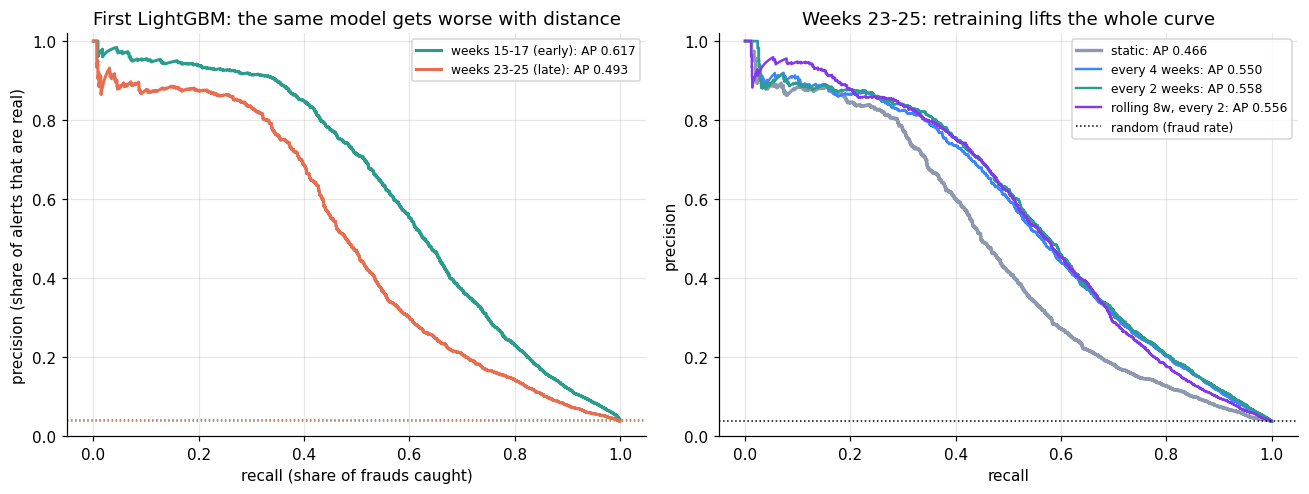

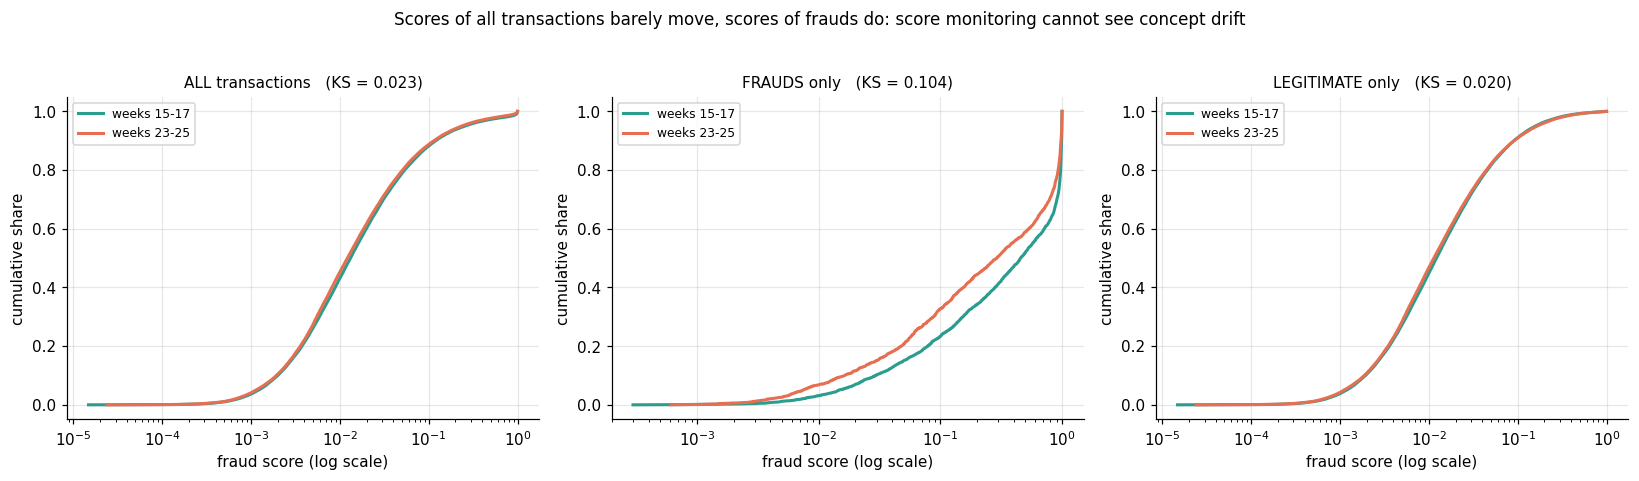

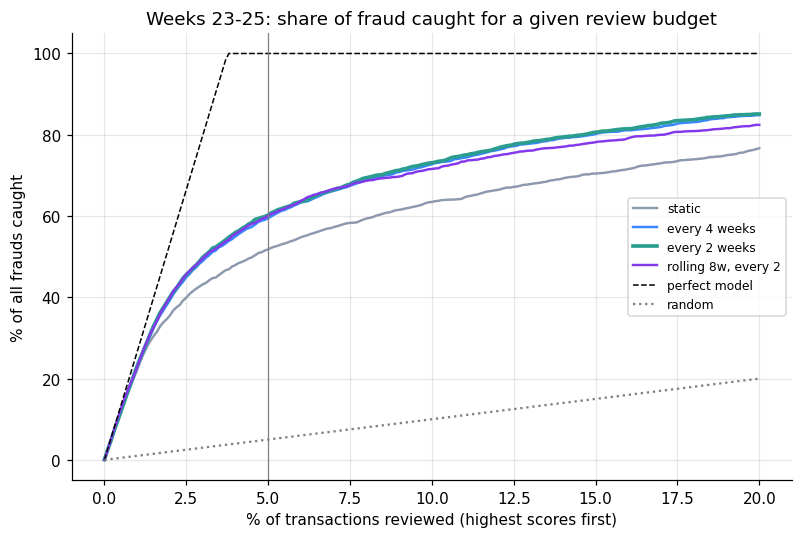

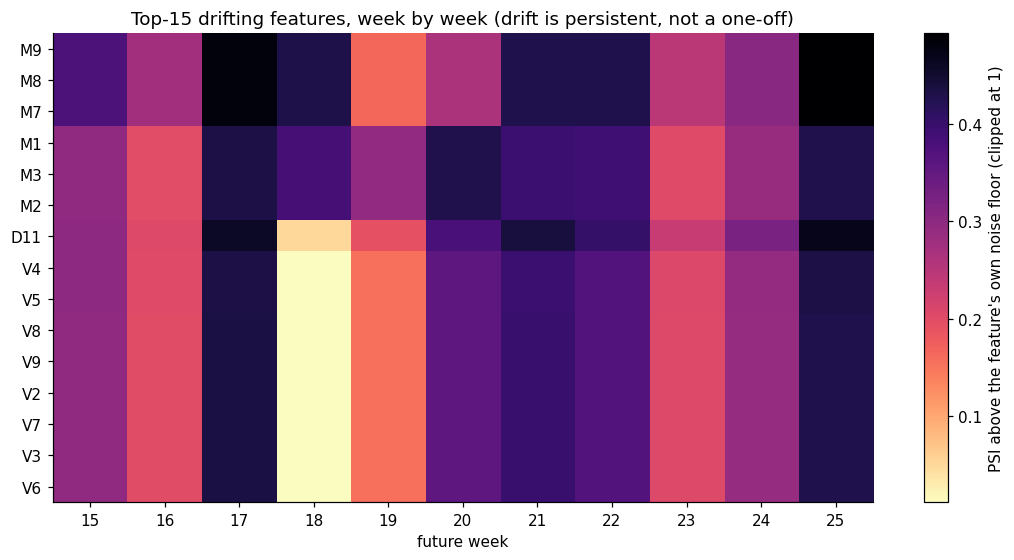

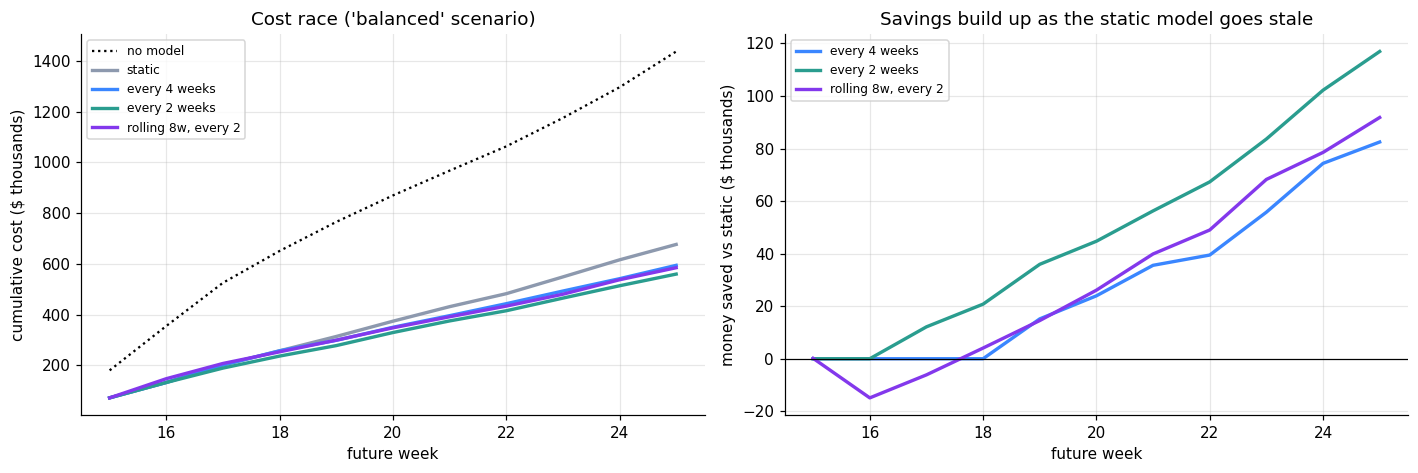

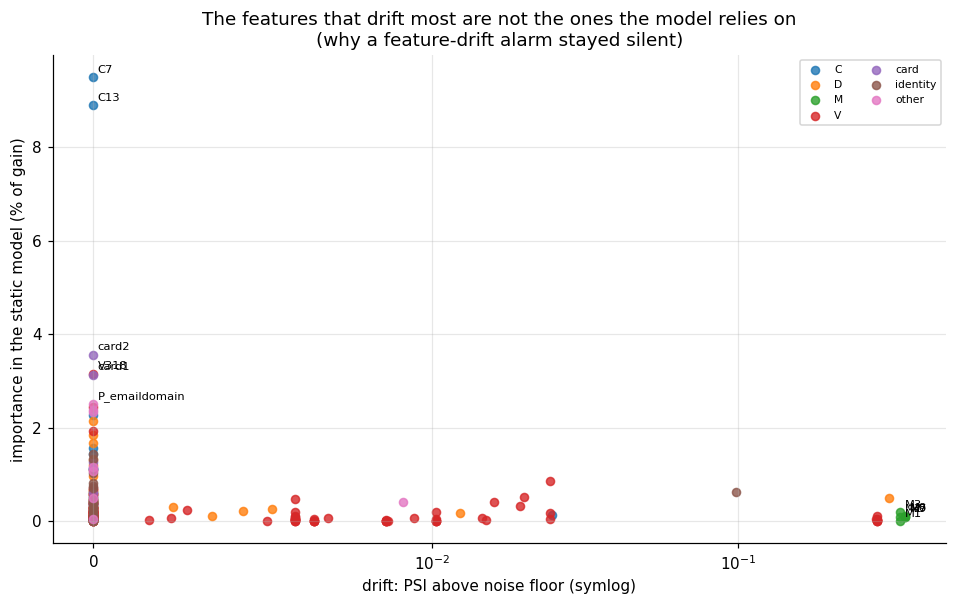

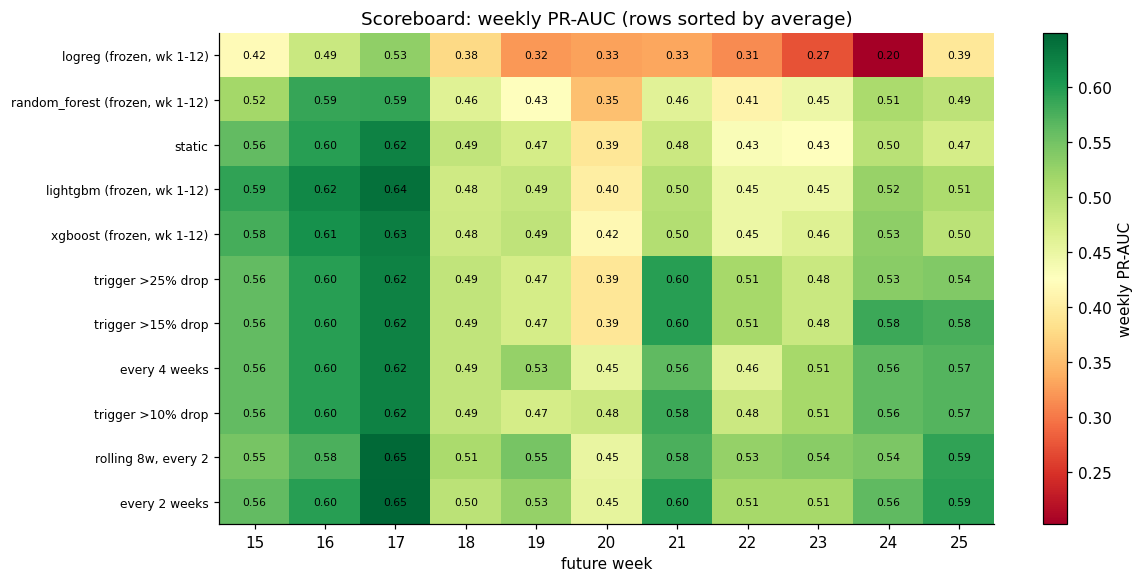

saved: ['liveL1_precision_recall_curves.png', 'liveL2_score_distributions.png', 'liveL3_cumulative_gain.png', 'liveL4_weekly_drift_heatmap.png', 'liveL5_cumulative_cost.png', 'liveL6_drift_vs_importance.png', 'liveL7_scoreboard.png']


In [38]:
# ======================= EXTRA FIGURES, SET 2: drawn from your live notebook state =======================
# Run AFTER the clean notebook through Part 10 (needs the variables checked below). Takes about 1-3 minutes.
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.metrics import precision_recall_curve, average_precision_score

need = ["y_test", "wk_t", "scores", "strategy_scores", "res", "psi", "model_cache", "cost_threshold", "model_key",
        "cost_vectors", "scenarios", "amt", "week", "y", "X", "train_mask", "test_weeks", "avg"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Run the clean notebook through Part 10 first. Missing: {missing}"

OUT = "/kaggle/working/report/extra"
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.tight_layout(); fig.savefig(f"{OUT}/{name}.png", dpi=200, bbox_inches="tight"); plt.show()

early_t, late_t = np.isin(wk_t, [15, 16, 17]), np.isin(wk_t, [23, 24, 25])        # masks over the future-test rows
early_r, late_r = np.isin(week, [15, 16, 17]), np.isin(week, [23, 24, 25])        # masks over all rows
s_lgb = scores["lightgbm"]

# ------------------------------------------------------------------ L1. precision-recall curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for m, lab, c in [(early_t, "weeks 15-17 (early)", "#2a9d8f"), (late_t, "weeks 23-25 (late)", "#e76f51")]:
    p, r, _ = precision_recall_curve(y_test[m], s_lgb[m])
    ax[0].plot(r, p, color=c, lw=2, label=f"{lab}: AP {average_precision_score(y_test[m], s_lgb[m]):.3f}")
    ax[0].axhline(y_test[m].mean(), color=c, ls=":", lw=1)
ax[0].set_xlabel("recall (share of frauds caught)"); ax[0].set_ylabel("precision (share of alerts that are real)")
ax[0].set_title("First LightGBM: the same model gets worse with distance"); ax[0].legend(fontsize=8); ax[0].set_ylim(0, 1.02)
for name, c in [("static", "#8d99ae"), ("every 4 weeks", "#3a86ff"), ("every 2 weeks", "#2a9d8f"), ("rolling 8w, every 2", "#8338ec")]:
    s = strategy_scores[name][late_r]; p, r, _ = precision_recall_curve(y[late_r], s)
    ax[1].plot(r, p, lw=2.2 if name == "static" else 1.6, color=c, label=f"{name}: AP {average_precision_score(y[late_r], s):.3f}")
ax[1].axhline(y[late_r].mean(), color="k", ls=":", lw=1, label="random (fraud rate)")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Weeks 23-25: retraining lifts the whole curve"); ax[1].legend(fontsize=8); ax[1].set_ylim(0, 1.02)
save(fig, "liveL1_precision_recall_curves")

# ------------------------------------------------------------------ L2. score distributions: why score monitoring is blind (Proposition 1)
def ecdf(a):
    a = np.sort(a); return a, np.arange(1, len(a) + 1) / len(a)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for k, (title, base) in enumerate([("ALL transactions", np.ones(len(y_test), bool)), ("FRAUDS only", y_test == 1), ("LEGITIMATE only", y_test == 0)]):
    a, b = s_lgb[early_t & base], s_lgb[late_t & base]
    for v, lab, c in [(a, "weeks 15-17", "#2a9d8f"), (b, "weeks 23-25", "#e76f51")]:
        xs, ys = ecdf(v); ax[k].plot(xs, ys, color=c, lw=2, label=lab)
    ax[k].set_xscale("log"); ax[k].set_xlabel("fraud score (log scale)"); ax[k].set_ylabel("cumulative share")
    ax[k].set_title(f"{title}   (KS = {ks_2samp(a, b).statistic:.3f})", fontsize=10); ax[k].legend(fontsize=8)
fig.suptitle("Scores of all transactions barely move, scores of frauds do: score monitoring cannot see concept drift", fontsize=11, y=1.03)
save(fig, "liveL2_score_distributions")

# ------------------------------------------------------------------ L3. cumulative gain (what a review budget buys)
fig, ax = plt.subplots(figsize=(7.4, 5))
grid = np.linspace(0, .20, 201)
def gain(yy, s):
    o = np.argsort(-s); cum = np.cumsum(yy[o]) / yy.sum(); idx = (grid * len(yy)).astype(int).clip(1, len(yy)) - 1
    return cum[idx]
for name, c in [("static", "#8d99ae"), ("every 4 weeks", "#3a86ff"), ("every 2 weeks", "#2a9d8f"), ("rolling 8w, every 2", "#8338ec")]:
    ax.plot(grid * 100, gain(y[late_r], strategy_scores[name][late_r]) * 100, lw=2.4 if name == "every 2 weeks" else 1.6, color=c, label=name)
fr_late = y[late_r].mean()
ax.plot(grid * 100, np.minimum(grid / fr_late, 1) * 100, "k--", lw=1, label="perfect model")
ax.plot(grid * 100, grid * 100, color="gray", ls=":", label="random")
ax.axvline(5, color="gray", lw=.8); ax.set_xlabel("% of transactions reviewed (highest scores first)"); ax.set_ylabel("% of all frauds caught")
ax.set_title("Weeks 23-25: share of fraud caught for a given review budget"); ax.legend(fontsize=8)
save(fig, "liveL3_cumulative_gain")

# ------------------------------------------------------------------ L4. weekly drift heatmap of the top drifting features
top = res.head(15)
Xtr = X[train_mask]
wk_masks = {w: week == w for w in test_weeks}
H = np.array([[max(psi(Xtr[f].values, X.loc[wk_masks[w], f].values) - nf, 0.0) for w in test_weeks] for f, nf in zip(top.feature, top.noise_floor)])
fig, ax = plt.subplots(figsize=(10, 5.2))
im = ax.imshow(np.clip(H, 0, 1), cmap="magma_r", aspect="auto"); ax.grid(False)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.feature); ax.set_xticks(range(len(test_weeks))); ax.set_xticklabels(test_weeks)
ax.set_xlabel("future week"); plt.colorbar(im, label="PSI above the feature's own noise floor (clipped at 1)")
ax.set_title("Top-15 drifting features, week by week (drift is persistent, not a one-off)"); save(fig, "liveL4_weekly_drift_heatmap")

# ------------------------------------------------------------------ L5. cumulative cost race
sc_name, sc = "balanced", scenarios["balanced"]
def weekly_cost(name):
    out = []
    for w in test_weeks:
        idx = np.where(week == w)[0]
        flag = strategy_scores[name][idx] >= cost_threshold(model_key(name, w), sc_name)
        fp, fn = cost_vectors(y[idx], amt[idx], sc)
        out.append(fp[flag].sum() + fn[~flag].sum())
    return np.array(out)
names5 = ["static", "every 4 weeks", "every 2 weeks", "rolling 8w, every 2"]
cum = {n: np.cumsum(weekly_cost(n)) for n in names5}
nomodel = np.cumsum([cost_vectors(y[week == w], amt[week == w], sc)[1].sum() for w in test_weeks])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].plot(test_weeks, nomodel / 1e3, "k:", label="no model")
for n, c in zip(names5, ["#8d99ae", "#3a86ff", "#2a9d8f", "#8338ec"]): ax[0].plot(test_weeks, cum[n] / 1e3, lw=2.2, color=c, label=n)
ax[0].set_xlabel("future week"); ax[0].set_ylabel("cumulative cost ($ thousands)"); ax[0].set_title(f"Cost race ('{sc_name}' scenario)"); ax[0].legend(fontsize=8)
for n, c in zip(names5[1:], ["#3a86ff", "#2a9d8f", "#8338ec"]): ax[1].plot(test_weeks, (cum["static"] - cum[n]) / 1e3, lw=2.2, color=c, label=n)
ax[1].axhline(0, color="k", lw=.8); ax[1].set_xlabel("future week"); ax[1].set_ylabel("money saved vs static ($ thousands)")
ax[1].set_title("Savings build up as the static model goes stale"); ax[1].legend(fontsize=8)
save(fig, "liveL5_cumulative_cost")

# ------------------------------------------------------------------ L6. drift vs importance
gain_imp = pd.Series(model_cache[(15, None)].booster_.feature_importance(importance_type="gain"), index=X.columns)
D = res.set_index("feature")[["excess", "family"]].join((gain_imp / gain_imp.sum() * 100).rename("importance"))
fig, ax = plt.subplots(figsize=(8.8, 5.6))
for f_, g in D.groupby("family"): ax.scatter(g.excess, g.importance, s=28, label=f_, alpha=.8)
lab = set(D.nlargest(6, "excess").index) | set(D.nlargest(6, "importance").index)
for f_ in lab: ax.annotate(f_, (D.loc[f_, "excess"], D.loc[f_, "importance"]), fontsize=7.5, xytext=(3, 3), textcoords="offset points")
ax.set_xscale("symlog", linthresh=.01); ax.set_xlabel("drift: PSI above noise floor (symlog)"); ax.set_ylabel("importance in the static model (% of gain)")
ax.set_title("The features that drift most are not the ones the model relies on\n(why a feature-drift alarm stayed silent)"); ax.legend(fontsize=7, ncol=2)
save(fig, "liveL6_drift_vs_importance")

# ------------------------------------------------------------------ L7. scoreboard: weekly PR-AUC of every model and strategy
rows = {}
for n, s in scores.items(): rows[f"{n} (frozen, wk 1-12)"] = [average_precision_score(y_test[wk_t == w], s[wk_t == w]) for w in test_weeks]
for n, s in strategy_scores.items(): rows[n] = [avg(s, [w]) for w in test_weeks]
Sb = pd.DataFrame(rows, index=test_weeks).T
Sb = Sb.loc[Sb.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(11, 5.4))
im = ax.imshow(Sb.values, cmap="RdYlGn", aspect="auto", vmin=np.nanmin(Sb.values), vmax=np.nanmax(Sb.values)); ax.grid(False)
for i in range(Sb.shape[0]):
    for j in range(Sb.shape[1]): ax.text(j, i, f"{Sb.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_yticks(range(Sb.shape[0])); ax.set_yticklabels(Sb.index, fontsize=8); ax.set_xticks(range(len(test_weeks))); ax.set_xticklabels(test_weeks)
ax.set_xlabel("future week"); plt.colorbar(im, label="weekly PR-AUC"); ax.set_title("Scoreboard: weekly PR-AUC (rows sorted by average)")
save(fig, "liveL7_scoreboard")
print("saved:", sorted(f for f in os.listdir(OUT) if f.startswith("live")))